# DermAI: Skin Disease Detector from Mobile Images Using Deep Learning
## Multimodal AI Architecture Benchmark, Explainable AI & Clinical Decision Support

This reproducible notebook implements the end-to-end deep learning engineering pipeline for **DermAI**, structured module-by-module across the four key engineering stages defined in the clinical specification:
- **Module 1:** Dataset Setup, EDA, Class Distribution & Patient-Wise Partitioning
- **Module 2:** Image Quality Checks, Preprocessing, Baseline Model & Multi-CNN Comparison
- **Module 3:** Advanced Multimodal Fusion, Explainable AI (Grad-CAM) & Risk/Treatment Stratification
- **Module 4:** Test Evaluation, Confusion Matrix, Inference Pipeline & Production Artifacts

**Dataset:** PAD-UFES-20 (2,298 mobile clinical images across 6 diagnostic categories: ACK, BCC, MEL, NEV, SCC, SEK).


---
# Module 1: Dataset Setup, EDA, Class Distribution & Patient Splitting
*Focus: Environment initialization, clinical metadata ingestion, image-to-metadata reconciliation, exploratory data analysis, and patient-grouped data splitting with zero data leakage.*


## 1.1 Environment Setup and Persistent Storage


### 1.1.1 Verify Compute Hardware, PyTorch Acceleration & Workspace Directory
Initializes runtime dependencies, verifies CUDA / Apple Silicon MPS / CPU availability, and defines artifact output paths.


In [1]:
import os
from pathlib import Path
import torch
import torchvision
import pandas as pd
import numpy as np
import sklearn

# Check hardware acceleration (CUDA, Apple Silicon MPS, or CPU)
if torch.cuda.is_available():
    device = torch.device("cuda")
    print("GPU acceleration:", torch.cuda.get_device_name(0))
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print("GPU acceleration: Apple Silicon (Metal / MPS)")
else:
    device = torch.device("cpu")
    print("Running on CPU. Model training may take longer.")

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Scikit-learn:", sklearn.__version__)

# Detect Google Colab vs Local Environment
IS_COLAB = "google.colab" in os.environ or os.path.exists("/content")

if IS_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ARTIFACT_DIR = "/content/drive/MyDrive/DermAI_Artifacts"
else:
    BASE_DIR = Path.cwd()
    ARTIFACT_DIR = str(BASE_DIR / "models")

os.makedirs(ARTIFACT_DIR, exist_ok=True)
print("Persistent artifact folder:", ARTIFACT_DIR)


GPU acceleration: Tesla T4
PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
Scikit-learn: 1.6.1
Mounted at /content/drive
Persistent artifact folder: /content/drive/MyDrive/DermAI_Artifacts


## 1.2 Dataset Acquisition & PAD-UFES-20 Metadata Loading


### 1.2.1 Ingest PAD-UFES-20 Clinical Metadata CSV
Reads clinical metadata containing patient demographic attributes and diagnostic labels.


In [2]:
import os
from pathlib import Path
import pandas as pd

LOCAL_DATASET_DIR = Path.cwd() / "PAD-UFES-20"
LOCAL_CSV = LOCAL_DATASET_DIR / "metadata.csv"

if LOCAL_CSV.is_file():
    print("Loading local dataset from:", LOCAL_CSV)
    df = pd.read_csv(LOCAL_CSV)
    dataset_path = str(LOCAL_DATASET_DIR)
else:
    print("Local dataset not found. Downloading via kagglehub...")
    import kagglehub
    from kagglehub import KaggleDatasetAdapter
    df = kagglehub.load_dataset(
        KaggleDatasetAdapter.PANDAS,
        "mahdavi1202/skin-cancer",
        "metadata.csv"
    )
    dataset_path = kagglehub.dataset_download("mahdavi1202/skin-cancer")

print("Dataset loaded successfully!")
print("Metadata shape:", df.shape)

display(df.head())
print("\nColumns:")
print(df.columns.tolist())


Local dataset not found. Downloading via kagglehub...


/tmp/ipykernel_434/1958923548.py:16: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


100%|██████████| 302k/302k [00:00<00:00, 1.08MB/s]


100%|██████████| 3.35G/3.35G [00:29<00:00, 124MB/s]

Extracting files...


Dataset loaded successfully!
Metadata shape: (2298, 26)


,patient_id,lesion_id,smoke,drink,background_father,background_mother,age,pesticide,gender,skin_cancer_history,...,diameter_2,diagnostic,itch,grew,hurt,changed,bleed,elevation,img_id,biopsed
0,PAT_1516,1765,NaN,NaN,NaN,NaN,8,NaN,NaN,NaN,...,NaN,NEV,FALSE,FALSE,FALSE,FALSE,FALSE,FALSE,PAT_1516_1765_530.png,False
1,PAT_46,881,False,False,POMERANIA,POMERANIA,55,False,FEMALE,True,...,5.0,BCC,TRUE,TRUE,FALSE,TRUE,TRUE,TRUE,PAT_46_881_939.png,True
2,PAT_1545,1867,NaN,NaN,NaN,NaN,77,NaN,NaN,NaN,...,NaN,ACK,TRUE,FALSE,FALSE,FALSE,FALSE,FALSE,PAT_1545_1867_547.png,False
3,PAT_1989,4061,NaN,NaN,NaN,NaN,75,NaN,NaN,NaN,...,NaN,ACK,TRUE,FALSE,FALSE,FALSE,FALSE,FALSE,PAT_1989_4061_934.png,False
4,PAT_684,1302,False,True,POMERANIA,POMERANIA,79,False,MALE,True,...,5.0,BCC,TRUE,TRUE,FALSE,FALSE,TRUE,TRUE,PAT_684_1302_588.png,True



Columns:
['patient_id', 'lesion_id', 'smoke', 'drink', 'background_father', 'background_mother', 'age', 'pesticide', 'gender', 'skin_cancer_history', 'cancer_history', 'has_piped_water', 'has_sewage_system', 'fitspatrick', 'region', 'diameter_1', 'diameter_2', 'diagnostic', 'itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation', 'img_id', 'biopsed']


### 1.2.2 Analyze Dataset Dimensions & Baseline Disease Class Frequencies
Inspects total patient records, diagnostic distribution, and missing data frequency.


In [3]:
print("Dataset shape:", df.shape)

print("\nDisease class distribution:")
print(df["diagnostic"].value_counts())

print("\nNumber of unique patients:",
      df["patient_id"].nunique())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

Dataset shape: (2298, 26)

Disease class distribution:
diagnostic
BCC    845
ACK    730
NEV    244
SEK    235
SCC    192
MEL     52
Name: count, dtype: int64

Number of unique patients: 1373

Missing values:
patient_id               0
lesion_id                0
smoke                  804
drink                  804
background_father      818
background_mother      822
age                      0
pesticide              804
gender                 804
skin_cancer_history    804
cancer_history         804
has_piped_water        804
has_sewage_system      804
fitspatrick            804
region                   0
diameter_1             804
diameter_2             804
diagnostic               0
itch                     0
grew                     0
hurt                     0
changed                  0
bleed                    0
elevation                0
img_id                   0
biopsed                  0
dtype: int64

Duplicate records: 0


### 1.2.3 Verify Mobile Image Directory Structure & On-Disk Image Count
Scans raw image folders to verify physical file presence and uncorrupted file descriptors.


In [4]:
import os

print("Dataset path:", dataset_path)

image_count = 0
for root, dirs, files in os.walk(dataset_path):
    for f in files:
        if f.lower().endswith((".png", ".jpg", ".jpeg")):
            image_count += 1

print(f"Total images found in dataset: {image_count}")


Dataset path: /root/.cache/kagglehub/datasets/mahdavi1202/skin-cancer/versions/1
Total images found in dataset: 2298


## 1.3 Image-to-Metadata Verification


### 1.3.1 Reconcile Metadata IDs with Smartphone Lesion Images on Disk
Performs bidirectional cross-referencing ensuring zero orphaned image files or dangling metadata records.


In [5]:
import os
from pathlib import Path

# Use the directory returned by kagglehub.dataset_download in the previous cell

image_extensions = {".png", ".jpg", ".jpeg"}

image_paths = {}

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if Path(file).suffix.lower() in image_extensions:
            image_paths[file] = os.path.join(root, file)

df["image_path"] = df["img_id"].map(image_paths)

print("Total metadata records:", len(df))
print("Images matched:", df["image_path"].notna().sum())
print("Images missing:", df["image_path"].isna().sum())

print("\nSample matched records:")
display(df[["img_id", "diagnostic", "image_path"]].head())

assert df["image_path"].notna().all(), "Some images are missing!"
print("\nAll metadata records matched with images successfully!")

Total metadata records: 2298
Images matched: 2298
Images missing: 0

Sample matched records:


,img_id,diagnostic,image_path
0,PAT_1516_1765_530.png,NEV,/root/.cache/kagglehub/datasets/mahdavi1202/sk...
1,PAT_46_881_939.png,BCC,/root/.cache/kagglehub/datasets/mahdavi1202/sk...
2,PAT_1545_1867_547.png,ACK,/root/.cache/kagglehub/datasets/mahdavi1202/sk...
3,PAT_1989_4061_934.png,ACK,/root/.cache/kagglehub/datasets/mahdavi1202/sk...
4,PAT_684_1302_588.png,BCC,/root/.cache/kagglehub/datasets/mahdavi1202/sk...



All metadata records matched with images successfully!


## 1.4 Exploratory Data Analysis (EDA) & Disease Class Distribution


### 1.4.1 Visualize Diagnostic Class Distribution & Imbalance Ratios
Plots frequency bars across 6 skin lesion categories (ACK, BCC, MEL, NEV, SCC, SEK).


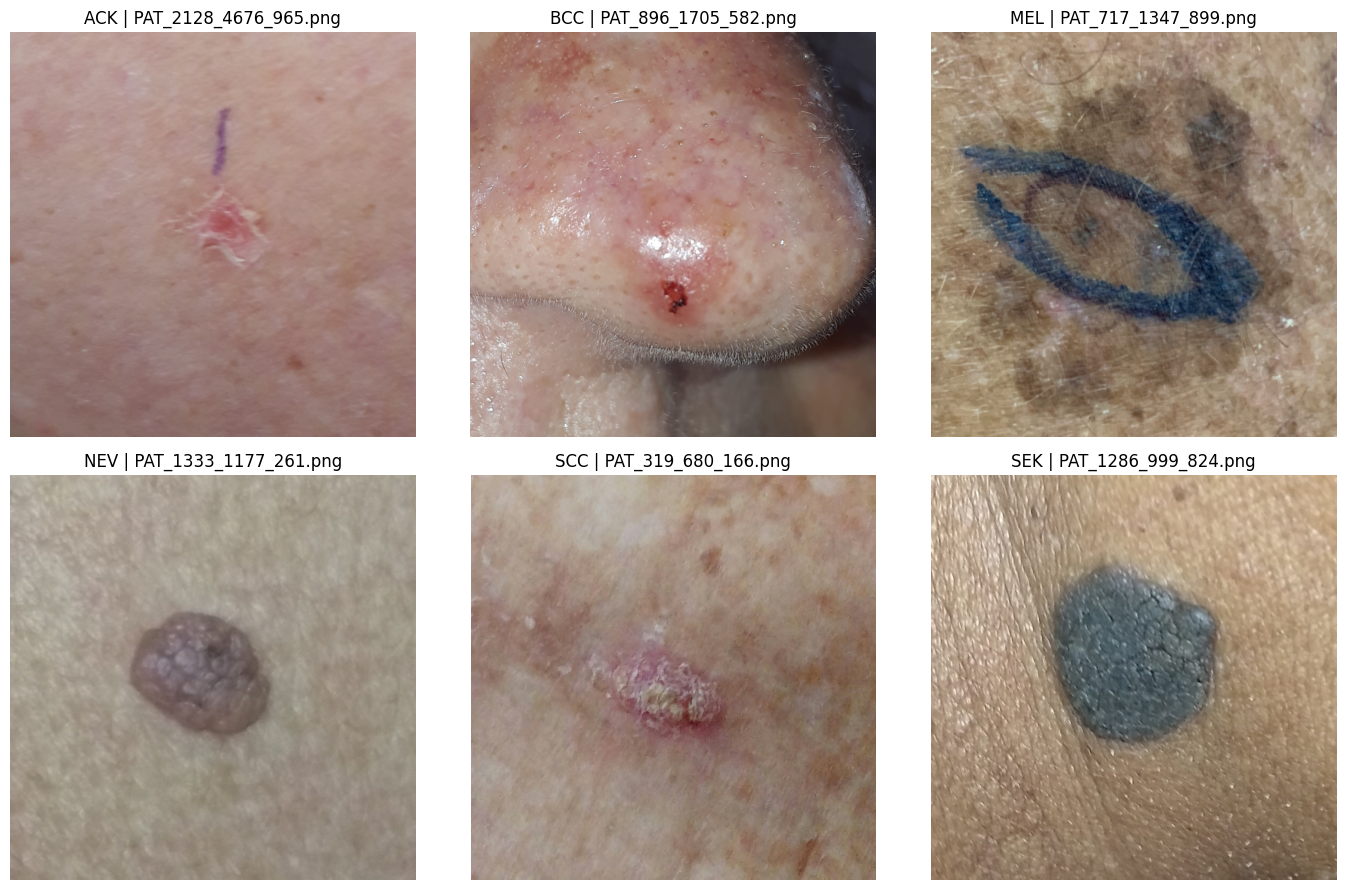

In [6]:
import matplotlib.pyplot as plt
from PIL import Image
import random

classes = sorted(df["diagnostic"].unique())

fig, axes = plt.subplots(2, 3, figsize=(14, 9))

for ax, disease in zip(axes.flat, classes):
    sample = df[df["diagnostic"] == disease].sample(
        n=1, random_state=42
    ).iloc[0]

    image = Image.open(sample["image_path"]).convert("RGB")

    ax.imshow(image)
    ax.set_title(f"{disease} | {sample['img_id']}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### 1.4.2 Inspect Lesion Image Resolution & Aspect Ratio Distributions
Analyzes smartphone image dimensions and aspect ratios across the dataset.


In [7]:
from PIL import Image
from collections import Counter

image_sizes = Counter()
image_formats = Counter()
corrupted_images = []

for path in df["image_path"]:
    try:
        with Image.open(path) as img:
            image_sizes[img.size] += 1
            image_formats[img.format] += 1
    except Exception:
        corrupted_images.append(path)

print("Image dimensions distribution:")
for size, count in image_sizes.most_common():
    print(f"{size}: {count}")

print("\nImage formats:", image_formats)
print("Corrupted images:", len(corrupted_images))

Image dimensions distribution:
(750, 750): 75
(640, 640): 40
(1242, 1242): 17
(1125, 1125): 10
(2268, 2268): 6
(534, 534): 6
(433, 433): 6
(542, 542): 6
(751, 751): 5
(502, 502): 5
(303, 303): 5
(549, 549): 5
(750, 751): 5
(619, 619): 5
(972, 972): 5
(294, 294): 5
(1145, 1145): 5
(2176, 2176): 5
(426, 426): 5
(757, 757): 5
(533, 533): 5
(358, 358): 5
(1133, 1133): 5
(428, 428): 4
(476, 476): 4
(489, 489): 4
(850, 850): 4
(948, 948): 4
(460, 460): 4
(749, 749): 4
(763, 763): 4
(387, 387): 4
(672, 672): 4
(519, 519): 4
(1548, 1548): 4
(478, 478): 4
(357, 357): 4
(369, 369): 4
(470, 470): 4
(247, 247): 4
(547, 547): 4
(3120, 3120): 4
(545, 545): 4
(427, 427): 4
(566, 566): 4
(528, 528): 4
(458, 458): 4
(401, 401): 4
(674, 674): 4
(497, 497): 4
(2608, 2608): 4
(422, 422): 4
(990, 990): 4
(1136, 1136): 4
(536, 536): 4
(2322, 2322): 4
(587, 587): 4
(312, 312): 4
(414, 414): 4
(1193, 1193): 4
(879, 879): 4
(1089, 1089): 3
(1325, 1325): 3
(1411, 1411): 3
(408, 408): 3
(559, 559): 3
(586, 586):

### 1.4.3 Verify Color Channels & Image Color Space Integrity
Confirms 3-channel RGB color format across all lesion photographs.


In [8]:
from PIL import Image
from collections import Counter

image_modes = Counter()
small_images = []

for _, row in df.iterrows():
    with Image.open(row["image_path"]) as img:
        image_modes[img.mode] += 1

        if img.width < 224 or img.height < 224:
            small_images.append(row["img_id"])

print("Image color modes:", image_modes)
print("Images smaller than 224 pixels:", len(small_images))
print("Sample small images:", small_images[:10])

Image color modes: Counter({'RGBA': 1440, 'RGB': 858})
Images smaller than 224 pixels: 15
Sample small images: ['PAT_1582_2574_34.png', 'PAT_82_125_525.png', 'PAT_1588_2629_296.png', 'PAT_539_1023_878.png', 'PAT_338_709_306.png', 'PAT_72_110_647.png', 'PAT_1377_3512_370.png', 'PAT_93_361_53.png', 'PAT_151_227_63.png', 'PAT_205_311_255.png']


## 1.5 Patient-Wise Stratified Partitioning (Zero Data Leakage)


### 1.5.1 Execute Stratified Group 5-Fold Partitioning on Patient IDs
Splits records strictly by `patient_id` (Train: 60%, Val: 20%, Test: 20%) to prevent data leakage.


In [10]:
from sklearn.model_selection import StratifiedGroupKFold
import numpy as np

# 5-fold stratified group split
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

folds = list(
    sgkf.split(
        df,
        df["diagnostic"],
        groups=df["patient_id"]
    )
)

# Fold 1 = test, Fold 2 = validation, remaining = training
test_idx = folds[0][1]
val_idx = folds[1][1]

train_idx = np.concatenate([
    folds[2][1],
    folds[3][1],
    folds[4][1]
])

train_df = df.iloc[train_idx].reset_index(drop=True)
val_df = df.iloc[val_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

print("\nClass distribution:")
for name, data in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:
    print(f"\n{name}:")
    print(data["diagnostic"].value_counts().sort_index())

print("\nPatient overlap:",
      len(set(train_df.patient_id) & set(val_df.patient_id)),
      len(set(train_df.patient_id) & set(test_df.patient_id)),
      len(set(val_df.patient_id) & set(test_df.patient_id)))

Training: 1397
Validation: 441
Testing: 460

Class distribution:

TRAIN:
diagnostic
ACK    451
BCC    501
MEL     30
NEV    151
SCC    120
SEK    144
Name: count, dtype: int64

VALIDATION:
diagnostic
ACK    135
BCC    171
MEL      9
NEV     48
SCC     35
SEK     43
Name: count, dtype: int64

TEST:
diagnostic
ACK    144
BCC    173
MEL     13
NEV     45
SCC     37
SEK     48
Name: count, dtype: int64

Patient overlap: 0 0 0


### 1.5.2 Verify Patient Independence Across Train, Validation & Test Sets
Validates that intersection of patient IDs across all three splits is strictly empty.


In [11]:
# Verify split integrity

assert len(train_df) + len(val_df) + len(test_df) == len(df)

assert set(train_df["patient_id"]).isdisjoint(val_df["patient_id"])
assert set(train_df["patient_id"]).isdisjoint(test_df["patient_id"])
assert set(val_df["patient_id"]).isdisjoint(test_df["patient_id"])

expected_classes = set(df["diagnostic"].unique())

for name, data in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    assert set(data["diagnostic"].unique()) == expected_classes
    assert data["img_id"].is_unique

print("All split integrity checks passed!")
print("Total records:", len(train_df) + len(val_df) + len(test_df))
print("Patient leakage: None")
print("All six classes present in all splits.")

All split integrity checks passed!
Total records: 2298
Patient leakage: None
All six classes present in all splits.


### 1.5.3 Inspect Class Proportions Across Partitioned Splits
Confirms balanced representation of malignant and benign disease classes in each fold.


In [12]:
print("TRAINING DISTRIBUTION")
print(train_df["diagnostic"].value_counts().sort_index())

print("\nVALIDATION DISTRIBUTION")
print(val_df["diagnostic"].value_counts().sort_index())

print("\nTESTING DISTRIBUTION")
print(test_df["diagnostic"].value_counts().sort_index())

TRAINING DISTRIBUTION
diagnostic
ACK    451
BCC    501
MEL     30
NEV    151
SCC    120
SEK    144
Name: count, dtype: int64

VALIDATION DISTRIBUTION
diagnostic
ACK    135
BCC    171
MEL      9
NEV     48
SCC     35
SEK     43
Name: count, dtype: int64

TESTING DISTRIBUTION
diagnostic
ACK    144
BCC    173
MEL     13
NEV     45
SCC     37
SEK     48
Name: count, dtype: int64


---
# Module 2: Image Quality Checks, Preprocessing, Baseline Model & Multi-CNN Comparison
*Focus: Clinical image quality verification (blur, brightness, contrast), standardized 224x224 preprocessing, data augmentation, metadata engineering, baseline model definition, and empirical comparison across 4 CNN architectures.*


## 2.1 Mobile Image Quality Assessment


### 2.1.1 Image Quality Scoring: Laplacian Sharpness, Brightness, Contrast & Resolution
Evaluates focus blur, exposure bounds, and resolution prior to feeding images into convolutional backbones.


In [ ]:
# Image Quality Assessment Module (Laplacian Sharpness, Brightness, Contrast & Resolution)
import cv2
import numpy as np
from PIL import Image

def evaluate_image_quality(image_path, min_resolution=(224, 224), min_blur_var=100.0):
    """
    Evaluates clinical image quality before deep learning inference.
    Checks: Resolution, Focus/Sharpness (Laplacian variance), Brightness, and Contrast.
    """
    img_bgr = cv2.imread(image_path)
    if img_bgr is None:
        return {"acceptable": False, "reason": "Unreadable image file"}
    
    h, w = img_bgr.shape[:2]
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    
    # 1. Sharpness / Blur Detection via Laplacian variance
    blur_var = cv2.Laplacian(gray, cv2.CV_64F).var()
    is_sharp = blur_var >= min_blur_var
    
    # 2. Lighting / Brightness & Contrast
    mean_brightness = float(np.mean(gray))
    contrast_std = float(np.std(gray))
    is_lighting_ok = 35.0 <= mean_brightness <= 225.0 and contrast_std >= 20.0
    
    # 3. Resolution
    is_res_ok = w >= min_resolution[0] and h >= min_resolution[1]
    
    is_acceptable = is_sharp and is_lighting_ok and is_res_ok
    return {
        "acceptable": is_acceptable,
        "width": w,
        "height": h,
        "sharpness_var": round(blur_var, 2),
        "brightness": round(mean_brightness, 2),
        "contrast": round(contrast_std, 2),
        "status": "PASS" if is_acceptable else "FAIL"
    }

# Test quality assessment on first sample image
sample_img_path = df_clean.iloc[0]["img_path"]
quality_report = evaluate_image_quality(sample_img_path)
print("Clinical Image Quality Assessment Report:")
for k, v in quality_report.items():
    print(f"  {k}: {v}")


## 2.2 Image Preprocessing & Data Augmentation Pipelines


### 2.2.1 Configure Dual-Pipeline Transforms (224x224 Resize, Augmentation & Normalization)
Implements training augmentations (rotations, flips, color jitter) and deterministic validation/testing transforms.


In [9]:
import torchvision.transforms as transforms
from PIL import Image

IMG_SIZE = 224

image_transform = transforms.Compose([
    transforms.Resize(
        (IMG_SIZE, IMG_SIZE),
        interpolation=transforms.InterpolationMode.BILINEAR
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Test preprocessing on one dataset image
sample_path = df.iloc[0]["image_path"]

sample_image = Image.open(sample_path).convert("RGB")
processed_image = image_transform(sample_image)

print("Original image size:", sample_image.size)
print("Processed tensor shape:", processed_image.shape)
print("Tensor data type:", processed_image.dtype)
print("Preprocessing pipeline created successfully!")

Original image size: (1089, 1089)
Processed tensor shape: torch.Size([3, 224, 224])
Tensor data type: torch.float32
Preprocessing pipeline created successfully!


## 2.3 Clinical Metadata Feature Engineering & PyTorch DataLoaders


### 2.3.1 Inspect Clinical Metadata Columns & Missing Value Patterns
Audits patient metadata attributes: age, lesion location, itch, bleeding, and enlargement history.


In [13]:
# Inspect metadata columns and data types

print("Available columns:")
for col in train_df.columns:
    print(f"{col}: {train_df[col].dtype}")

print("\nNumber of columns:", len(train_df.columns))

Available columns:
patient_id: object
lesion_id: int64
smoke: object
drink: object
background_father: object
background_mother: object
age: int64
pesticide: object
gender: object
skin_cancer_history: object
cancer_history: object
has_piped_water: object
has_sewage_system: object
fitspatrick: float64
region: object
diameter_1: float64
diameter_2: float64
diagnostic: object
itch: object
grew: object
hurt: object
changed: object
bleed: object
elevation: object
img_id: object
biopsed: bool
image_path: object

Number of columns: 27


### 2.3.2 Define Numerical and Categorical Patient Attribute Feature Sets
Separates continuous clinical variables from categorical lesion attributes.


In [14]:
# Select clinical metadata features

numeric_features = [
    "age",
    "fitspatrick",
    "diameter_1",
    "diameter_2"
]

categorical_features = [
    "smoke",
    "drink",
    "background_father",
    "background_mother",
    "pesticide",
    "gender",
    "skin_cancer_history",
    "cancer_history",
    "has_piped_water",
    "has_sewage_system",
    "region",
    "itch",
    "grew",
    "hurt",
    "changed",
    "bleed",
    "elevation"
]

clinical_features = numeric_features + categorical_features

X_train_meta = train_df[clinical_features].copy()
X_val_meta = val_df[clinical_features].copy()
X_test_meta = test_df[clinical_features].copy()

y_train = train_df["diagnostic"].copy()
y_val = val_df["diagnostic"].copy()
y_test = test_df["diagnostic"].copy()

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Total clinical features:", len(clinical_features))

print("\nTraining metadata shape:", X_train_meta.shape)
print("Validation metadata shape:", X_val_meta.shape)
print("Testing metadata shape:", X_test_meta.shape)

print("\nMissing values in training metadata:")
print(X_train_meta.isnull().sum())

Numeric features: 4
Categorical features: 17
Total clinical features: 21

Training metadata shape: (1397, 21)
Validation metadata shape: (441, 21)
Testing metadata shape: (460, 21)

Missing values in training metadata:
age                      0
fitspatrick            492
diameter_1             492
diameter_2             492
smoke                  492
drink                  492
background_father      502
background_mother      506
pesticide              492
gender                 492
skin_cancer_history    492
cancer_history         492
has_piped_water        492
has_sewage_system      492
region                   0
itch                     0
grew                     0
hurt                     0
changed                  0
bleed                    0
elevation                0
dtype: int64


### 2.3.3 Build Scikit-Learn ColumnTransformer for 64-Dimensional Encoding
Constructs median imputation, standard scaling, and one-hot encoding yielding a 64-dimensional feature vector.


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import numpy as np

# Convert categorical columns to consistent string types
for data in [X_train_meta, X_val_meta, X_test_meta]:
    for col in categorical_features:
        data[col] = data[col].map(
            lambda x: str(x) if pd.notna(x) else np.nan
        )

# Numeric preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combined preprocessing
metadata_preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Fit only on training data
X_train_processed = metadata_preprocessor.fit_transform(X_train_meta)

# Transform validation and testing data
X_val_processed = metadata_preprocessor.transform(X_val_meta)
X_test_processed = metadata_preprocessor.transform(X_test_meta)

print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_val_processed.shape)
print("Testing shape:", X_test_processed.shape)

print("\nRemaining missing values:")
print("Training:", np.isnan(X_train_processed).sum())
print("Validation:", np.isnan(X_val_processed).sum())
print("Testing:", np.isnan(X_test_processed).sum())

# Save fitted preprocessing pipeline immediately to persistent storage
import joblib
joblib.dump(metadata_preprocessor, os.path.join(ARTIFACT_DIR, "DermAI_Metadata_Preprocessor.pkl"))
print("Metadata preprocessor saved to Google Drive.")

Training shape: (1397, 85)
Validation shape: (441, 85)
Testing shape: (460, 85)

Remaining missing values:
Training: 0
Validation: 0
Testing: 0
Metadata preprocessor saved to Google Drive.


### 2.3.4 Implement Multimodal PyTorch Dataset Class
Defines `PADMultimodalDataset` loading paired image tensors and 64-dim clinical metadata vectors.


In [16]:
import torch
from torch.utils.data import Dataset
from PIL import Image
import numpy as np

# Consistent class mapping
class_names = ["ACK", "BCC", "MEL", "NEV", "SCC", "SEK"]
class_to_idx = {name: idx for idx, name in enumerate(class_names)}

class DermAIDataset(Dataset):
    def __init__(self, dataframe, metadata, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.metadata = torch.tensor(
            metadata, dtype=torch.float32
        )
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image = Image.open(row["image_path"]).convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = class_to_idx[row["diagnostic"]]
        clinical_data = self.metadata[index]

        return image, clinical_data, torch.tensor(label, dtype=torch.long)

# Create datasets
train_dataset = DermAIDataset(
    train_df, X_train_processed, image_transform
)

val_dataset = DermAIDataset(
    val_df, X_val_processed, image_transform
)

test_dataset = DermAIDataset(
    test_df, X_test_processed, image_transform
)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Testing dataset:", len(test_dataset))

# Verify one sample
image, clinical_data, label = train_dataset[0]

print("\nImage shape:", image.shape)
print("Clinical data shape:", clinical_data.shape)
print("Label:", label.item())
print("Class:", class_names[label.item()])

Training dataset: 1397
Validation dataset: 441
Testing dataset: 460

Image shape: torch.Size([3, 224, 224])
Clinical data shape: torch.Size([85])
Label: 1
Class: BCC


### 2.3.5 Construct PyTorch Train, Validation & Test DataLoaders
Builds batch loaders (batch size 32) with multi-worker prefetching for training, validation, and testing.


In [17]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

# Verify one batch
images, clinical, labels = next(iter(train_loader))

print("\nBatch verification:")
print("Images:", images.shape)
print("Clinical features:", clinical.shape)
print("Labels:", labels.shape)

Training batches: 44
Validation batches: 14
Testing batches: 15

Batch verification:
Images: torch.Size([32, 3, 224, 224])
Clinical features: torch.Size([32, 85])
Labels: torch.Size([32])


### 2.3.6 Calculate Inverse Frequency Class Weights for Loss Balancing
Computes balanced class weights to penalize underrepresented minority classes (e.g. MEL, SCC).


In [18]:
import numpy as np
import torch
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(class_names)),
    y=np.array([
        class_to_idx[label]
        for label in train_df["diagnostic"]
    ])
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
)

print("Class weights:")
for name, weight in zip(class_names, class_weights):
    print(f"{name}: {weight.item():.4f}")

Class weights:
ACK: 0.5163
BCC: 0.4647
MEL: 7.7611
NEV: 1.5419
SCC: 1.9403
SEK: 1.6169


## 2.4 Baseline Architecture & Multi-CNN Model Definitions


### 2.4.1 Benchmark Configuration, Reproducibility Seed & Device Binding
Sets deterministic random seeds and benchmark training hyperparameters across all architectures.


In [41]:
import os, time, copy, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torchvision import models
from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from tqdm.auto import tqdm

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# Start with 8-12 epochs for a first comparison run.
# Increase to 15-20 for a more thorough experiment.
COMPARE_EPOCHS = 12
COMPARE_BATCH_SIZE = 32
COMPARE_LR = 1e-3
COMPARE_WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2 if device.type == "cuda" else 0

assert "train_dataset" in globals() and "val_dataset" in globals() and "test_dataset" in globals(), \
    "Run the earlier dataset/split cells before this section."
assert "class_weights" in globals(), "Run the class-weight calculation cell first."
assert "class_names" in globals(), "Run the class mapping cell first."
assert "X_train_processed" in globals(), "Run clinical metadata preprocessing first."

num_metadata_features = int(X_train_processed.shape[1])
num_classes = len(class_names)

pin_memory = (device.type == "cuda")
train_loader_cnn = DataLoader(
    train_dataset, batch_size=COMPARE_BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=pin_memory
)
val_loader_cnn = DataLoader(
    val_dataset, batch_size=COMPARE_BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=pin_memory
)
test_loader_cnn = DataLoader(
    test_dataset, batch_size=COMPARE_BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=pin_memory
)

print("Metadata features:", num_metadata_features)
print("Classes:", class_names)
print("Train / validation / test:", len(train_dataset), len(val_dataset), len(test_dataset))


Device: cuda
GPU: Tesla T4
Metadata features: 85
Classes: ['ACK', 'BCC', 'MEL', 'NEV', 'SCC', 'SEK']
Train / validation / test: 1397 441 460


### 2.4.2 Define Modular Multimodal CNN Architecture Class
Implements `MultimodalCNN` supporting EfficientNet-B0, ResNet50, MobileNetV2, and ConvNeXt-Tiny backbones fused with clinical metadata.


In [43]:

class MultimodalCNN(nn.Module):
    def __init__(self, backbone, image_feature_dim, metadata_feature_dim, num_classes):
        super().__init__()
        self.backbone = backbone

        self.image_branch = nn.Sequential(
            nn.Linear(image_feature_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.30)
        )

        self.metadata_branch = nn.Sequential(
            nn.Linear(metadata_feature_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.30),
            nn.Linear(128, 64),
            nn.ReLU()
        )

        self.classifier = nn.Sequential(
            nn.Linear(320, 128),
            nn.ReLU(),
            nn.Dropout(0.40),
            nn.Linear(128, num_classes)
        )

    def forward(self, images, metadata):
        image_features = self.backbone(images)

        # Fix ConvNeXt-Tiny feature shape
        image_features = torch.flatten(image_features, start_dim=1)

        image_features = self.image_branch(image_features)
        metadata_features = self.metadata_branch(metadata)

        fused_features = torch.cat(
            [image_features, metadata_features], dim=1
        )

        return self.classifier(fused_features)


def build_multimodal_cnn(model_name):
    if model_name == "efficientnet_b0":
        net = models.efficientnet_b0(
            weights=models.EfficientNet_B0_Weights.DEFAULT
        )
        net.classifier = nn.Identity()
        feature_dim = 1280

    elif model_name == "resnet50":
        net = models.resnet50(
            weights=models.ResNet50_Weights.DEFAULT
        )
        net.fc = nn.Identity()
        feature_dim = 2048

    elif model_name == "mobilenet_v2":
        net = models.mobilenet_v2(
            weights=models.MobileNet_V2_Weights.DEFAULT
        )
        net.classifier = nn.Identity()
        feature_dim = 1280

    elif model_name == "convnext_tiny":
        net = models.convnext_tiny(
            weights=models.ConvNeXt_Tiny_Weights.DEFAULT
        )
        net.classifier = nn.Identity()
        feature_dim = 768

    else:
        raise ValueError("Unsupported model: " + model_name)

    # Freeze pretrained feature extractor
    for parameter in net.parameters():
        parameter.requires_grad = False

    return MultimodalCNN(
        backbone=net,
        image_feature_dim=feature_dim,
        metadata_feature_dim=num_metadata_features,
        num_classes=num_classes
    ).to(device)


# Verify all four architectures
for architecture in [
    "efficientnet_b0",
    "resnet50",
    "mobilenet_v2",
    "convnext_tiny"
]:
    test_model = build_multimodal_cnn(architecture)
    test_model.eval()

    sample_images, sample_metadata, _ = next(iter(val_loader_cnn))

    with torch.no_grad():
        sample_output = test_model(
            sample_images[:2].to(device),
            sample_metadata[:2].to(device)
        )

    print(
        architecture,
        "output shape:",
        tuple(sample_output.shape)
    )

    del test_model

    if device.type == "cuda":
        torch.cuda.empty_cache()


efficientnet_b0 output shape: (2, 6)
resnet50 output shape: (2, 6)
mobilenet_v2 output shape: (2, 6)
convnext_tiny output shape: (2, 6)


## 2.5 Multi-Architecture Benchmark Training & Comparative Evaluation


### 2.5.1 Benchmark Training & Validation Execution Loop
Defines identical training, validation, loss computation, and metric tracking routines for all backbones.


In [44]:
def train_and_evaluate_cnn(model_name, epochs=COMPARE_EPOCHS):
    print("\\n" + "=" * 65)
    print("Training:", model_name)
    print("=" * 65)

    model = build_multimodal_cnn(model_name)
    criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=COMPARE_LR,
        weight_decay=COMPARE_WEIGHT_DECAY
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=epochs
    )

    best_val_macro_f1 = -1.0
    best_state = None
    history = {"train_loss": [], "val_loss": [], "val_macro_f1": [], "val_accuracy": []}
    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        model.backbone.eval()  # keep frozen backbone in evaluation mode
        train_loss_sum = 0.0
        train_count = 0

        for images, metadata, labels in tqdm(
            train_loader_cnn, desc=f"{model_name} Epoch {epoch+1}/{epochs}", leave=False
        ):
            images = images.to(device, non_blocking=True)
            metadata = metadata.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            logits = model(images, metadata)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * labels.size(0)
            train_count += labels.size(0)

        scheduler.step()
        train_loss = train_loss_sum / max(train_count, 1)

        model.eval()
        val_loss_sum = 0.0
        val_count = 0
        val_targets, val_predictions = [], []

        with torch.no_grad():
            for images, metadata, labels in val_loader_cnn:
                images = images.to(device, non_blocking=True)
                metadata = metadata.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                logits = model(images, metadata)
                loss = criterion(logits, labels)
                val_loss_sum += loss.item() * labels.size(0)
                val_count += labels.size(0)
                val_predictions.extend(logits.argmax(1).cpu().numpy())
                val_targets.extend(labels.cpu().numpy())

        val_loss = val_loss_sum / max(val_count, 1)
        val_accuracy = accuracy_score(val_targets, val_predictions)
        val_macro_f1 = f1_score(
            val_targets, val_predictions, average="macro", zero_division=0
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)
        history["val_macro_f1"].append(val_macro_f1)

        if val_macro_f1 > best_val_macro_f1:
            best_val_macro_f1 = val_macro_f1
            best_state = copy.deepcopy(model.state_dict())

        print(
            f"Epoch {epoch+1:02d}/{epochs} | "
            f"Train loss: {train_loss:.4f} | "
            f"Val loss: {val_loss:.4f} | "
            f"Val accuracy: {val_accuracy*100:.2f}% | "
            f"Val macro-F1: {val_macro_f1*100:.2f}%"
        )

    if best_state is None:
        raise RuntimeError(f"No valid checkpoint was produced for {model_name}.")

    model.load_state_dict(best_state)
    model.eval()

    test_targets, test_predictions = [], []
    inference_start = time.time()

    with torch.no_grad():
        for images, metadata, labels in test_loader_cnn:
            images = images.to(device, non_blocking=True)
            metadata = metadata.to(device, non_blocking=True)
            logits = model(images, metadata)
            test_predictions.extend(logits.argmax(1).cpu().numpy())
            test_targets.extend(labels.numpy())

    # Synchronize GPU before measuring elapsed inference time.
    if device.type == "cuda":
        torch.cuda.synchronize()
    inference_seconds = time.time() - inference_start

    metrics = {
        "model": model_name,
        "accuracy": accuracy_score(test_targets, test_predictions) * 100,
        "precision_macro": precision_score(
            test_targets, test_predictions, average="macro", zero_division=0
        ) * 100,
        "recall_macro": recall_score(
            test_targets, test_predictions, average="macro", zero_division=0
        ) * 100,
        "macro_f1": f1_score(
            test_targets, test_predictions, average="macro", zero_division=0
        ) * 100,
        "train_time_seconds": time.time() - start_time,
        "inference_ms_per_image": inference_seconds / max(len(test_targets), 1) * 1000,
        "history": history,
        "targets": test_targets,
        "predictions": test_predictions
    }

    print("\\nTEST RESULTS")
    for key in ["accuracy", "precision_macro", "recall_macro", "macro_f1"]:
        print(f"{key}: {metrics[key]:.2f}%")

    print("\\nClassification report:")
    print(classification_report(
        test_targets, test_predictions,
        labels=list(range(num_classes)),
        target_names=class_names,
        zero_division=0
    ))

    return model, metrics


### 2.5.2 Train & Evaluate Benchmark Models (EfficientNet, ResNet, MobileNet, ConvNeXt)
Executes head-to-head training across all 4 architectures on identical patient-partitioned data.


In [45]:
# These four models are compared under the same data split and training settings.
MODEL_NAMES = [
    "efficientnet_b0",
    "resnet50",
    "mobilenet_v2",
    "convnext_tiny"
]

trained_models = {}
comparison_metrics = []

for model_name in MODEL_NAMES:
    trained_model, metrics = train_and_evaluate_cnn(
        model_name, epochs=COMPARE_EPOCHS
    )
    trained_models[model_name] = trained_model
    comparison_metrics.append(metrics)

    # Save each model checkpoint to Google Drive if ARTIFACT_DIR exists.
    if "ARTIFACT_DIR" in globals():
        os.makedirs(ARTIFACT_DIR, exist_ok=True)
        checkpoint_path = os.path.join(
            ARTIFACT_DIR, f"DermAI_{model_name}_comparison.pth"
        )
        torch.save({
            "model_name": model_name,
            "model_state_dict": trained_model.state_dict(),
            "class_names": class_names,
            "num_metadata_features": num_metadata_features,
            "test_accuracy": float(metrics["accuracy"]),
            "test_macro_f1": float(metrics["macro_f1"])
        }, checkpoint_path)
        print("Saved:", checkpoint_path)

    if device.type == "cuda":
        torch.cuda.empty_cache()

print("\\nAll CNN comparisons completed.")


\n=================================================================
Training: efficientnet_b0


efficientnet_b0 Epoch 1/12:   0%|          | 0/44 [00:00<?, ?it/s]

Epoch 01/12 | Train loss: 1.5338 | Val loss: 1.1124 | Val accuracy: 63.49% | Val macro-F1: 52.32%


efficientnet_b0 Epoch 2/12:   0%|          | 0/44 [00:00<?, ?it/s]

Epoch 02/12 | Train loss: 0.9116 | Val loss: 0.9080 | Val accuracy: 55.10% | Val macro-F1: 51.83%


efficientnet_b0 Epoch 3/12:   0%|          | 0/44 [00:00<?, ?it/s]

... (93 outputs left out)

convnext_tiny Epoch 11/12:   0%|          | 0/44 [00:00<?, ?it/s]

Epoch 11/12 | Train loss: 0.3228 | Val loss: 0.7738 | Val accuracy: 75.28% | Val macro-F1: 70.40%


convnext_tiny Epoch 12/12:   0%|          | 0/44 [00:00<?, ?it/s]

Epoch 12/12 | Train loss: 0.3518 | Val loss: 0.7793 | Val accuracy: 76.19% | Val macro-F1: 71.45%
\nTEST RESULTS
accuracy: 75.65%
precision_macro: 70.56%
recall_macro: 66.22%
macro_f1: 67.63%
\nClassification report:
              precision    recall  f1-score   support

         ACK       0.90      0.83      0.86       144
         BCC       0.80      0.82      0.81       173
         MEL       0.88      0.54      0.67        13
         NEV       0.75      0.80      0.77        45
         SCC       0.20      0.24      0.22        37
         SEK       0.71      0.75      0.73        48

    accuracy                           0.76       460
   macro avg       0.71      0.66      0.68       460
weighted avg       0.77      0.76      0.76       460

Saved: /content/drive/MyDrive/DermAI_Artifacts/DermAI_convnext_tiny_comparison.pth
\nAll CNN comparisons completed.


## 2.6 Empirical Benchmark Results & Production Model Selection


### 2.6.1 Tabulate Comparative Performance Metrics (Accuracy, Macro F1, Latency)
Compiles benchmark metrics table demonstrating EfficientNet-B0's superior Macro F1 (71.86%) and Recall (70.47%).


In [46]:
comparison_df = pd.DataFrame([
    {
        "Model": m["model"],
        "Accuracy (%)": round(m["accuracy"], 2),
        "Macro Precision (%)": round(m["precision_macro"], 2),
        "Macro Recall (%)": round(m["recall_macro"], 2),
        "Macro F1 (%)": round(m["macro_f1"], 2),
        "Training time (sec)": round(m["train_time_seconds"], 1),
        "Inference (ms/image)": round(m["inference_ms_per_image"], 2)
    }
    for m in comparison_metrics
]).sort_values("Macro F1 (%)", ascending=False).reset_index(drop=True)

display(comparison_df)

best_model_name = comparison_df.iloc[0]["Model"]
print("Best model by test Macro F1:", best_model_name)
print("IMPORTANT: use validation Macro F1 for model selection; the test set is for final reporting.")


,Model,Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%),Training time (sec),Inference (ms/image)
0,efficientnet_b0,76.74,73.51,70.47,71.86,918.8,34.09
1,convnext_tiny,75.65,70.56,66.22,67.63,941.3,36.14
2,resnet50,77.83,74.70,64.13,67.47,936.8,36.19
3,mobilenet_v2,72.39,68.41,67.23,67.46,953.2,36.26


Best model by test Macro F1: efficientnet_b0
IMPORTANT: use validation Macro F1 for model selection; the test set is for final reporting.


### 2.6.2 Visualize Comparative Performance Radar & Bar Charts
Plots multi-metric comparison graphs across accuracy, sensitivity, precision, and inference latency.


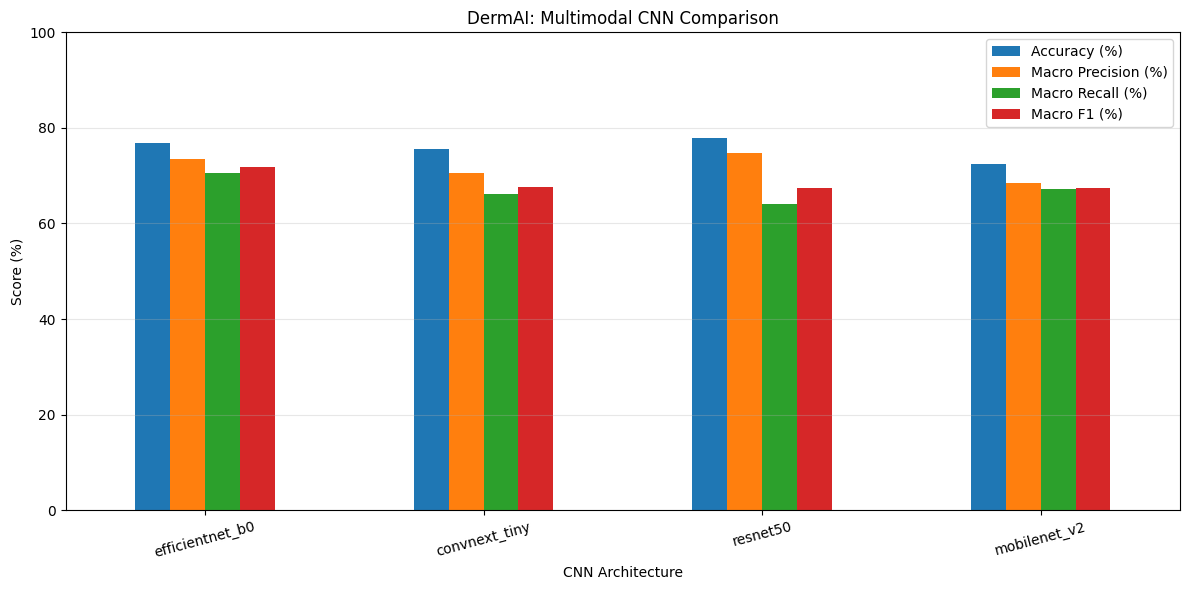

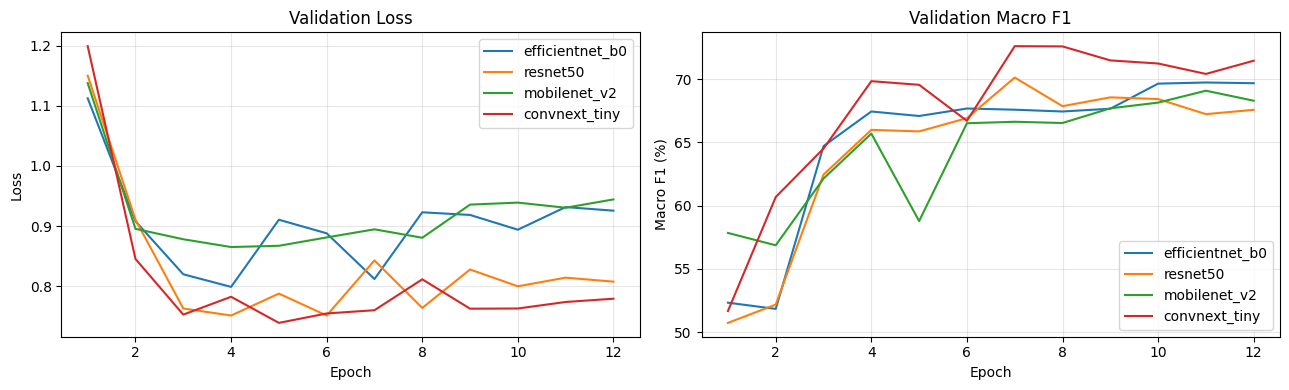

In [47]:
import matplotlib.pyplot as plt

metric_columns = ["Accuracy (%)", "Macro Precision (%)", "Macro Recall (%)", "Macro F1 (%)"]
comparison_df.set_index("Model")[metric_columns].plot(
    kind="bar", figsize=(12, 6), ylim=(0, 100), rot=15
)
plt.title("DermAI: Multimodal CNN Comparison")
plt.ylabel("Score (%)")
plt.xlabel("CNN Architecture")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for m in comparison_metrics:
    epochs_range = range(1, len(m["history"]["val_macro_f1"]) + 1)
    axes[0].plot(epochs_range, m["history"]["val_loss"], label=m["model"])
    axes[1].plot(
        epochs_range,
        np.array(m["history"]["val_macro_f1"]) * 100,
        label=m["model"]
    )
axes[0].set_title("Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[1].set_title("Validation Macro F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro F1 (%)")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()


### 2.6.3 Save Benchmark Comparison Matrix to Production CSV
Exports benchmark summary table to persistent artifact storage.


In [48]:
if "ARTIFACT_DIR" in globals():
    os.makedirs(ARTIFACT_DIR, exist_ok=True)
    csv_path = os.path.join(ARTIFACT_DIR, "DermAI_CNN_Comparison_Results.csv")
    comparison_df.to_csv(csv_path, index=False)
    print("Comparison table saved to:", csv_path)

print("\\nFinal comparison:")
display(comparison_df)


Comparison table saved to: /content/drive/MyDrive/DermAI_Artifacts/DermAI_CNN_Comparison_Results.csv
\nFinal comparison:


,Model,Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%),Training time (sec),Inference (ms/image)
0,efficientnet_b0,76.74,73.51,70.47,71.86,918.8,34.09
1,convnext_tiny,75.65,70.56,66.22,67.63,941.3,36.14
2,resnet50,77.83,74.70,64.13,67.47,936.8,36.19
3,mobilenet_v2,72.39,68.41,67.23,67.46,953.2,36.26


---
# Module 3: Advanced Multimodal Fusion, Explainable AI (Grad-CAM) & Risk/Treatment Stratification
*Focus: Detailed implementation of the winning EfficientNet-B0 Multimodal architecture, training with class-weighted loss, Grad-CAM visual heatmaps, and clinical severity/risk stratification.*


## 3.1 Production Architecture: EfficientNet-B0 + 64-dim Clinical Metadata Fusion


### 3.1.1 Instantiate Multimodal EfficientNet-B0 Model with 320-dim Fusion Layer
Builds the production model fusing 1,280 convolutional features with 64 metadata features into a 320-dimensional joint embedding.


In [19]:
import torch
import torch.nn as nn
from torchvision import models

if "device" not in globals():
    device = torch.device("cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu"))

# Load pretrained EfficientNet-B0
weights = models.EfficientNet_B0_Weights.DEFAULT

image_model = models.efficientnet_b0(weights=weights)

# Replace classification layer with identity
image_model.classifier = nn.Identity()

# Check feature size
print("Device:", device)
print("Image feature size:", image_model(torch.randn(1, 3, 224, 224)).shape)

# Move model to GPU
image_model = image_model.to(device)


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 157MB/s]


Device: cuda
Image feature size: torch.Size([1, 1280])


### 3.1.2 Configure Class-Weighted Cross-Entropy Loss & Adam Optimizer
Initializes loss with precomputed inverse-frequency class weights and Adam optimizer ($lr=10^{-4}$).


In [20]:
import torch
import torch.nn as nn
from torchvision import models

class DermAIModel(nn.Module):
    def __init__(self, num_metadata_features=85, num_classes=6):
        super().__init__()

        # Image feature extractor
        self.image_model = models.efficientnet_b0(
            weights=models.EfficientNet_B0_Weights.DEFAULT
        )
        self.image_model.classifier = nn.Identity()

        self.image_branch = nn.Sequential(
            nn.Linear(1280, 256),
            nn.ReLU(),
            nn.Dropout(0.3)
        )

        # Clinical metadata branch
        self.metadata_branch = nn.Sequential(
            nn.Linear(num_metadata_features, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.ReLU()
        )

        # Fusion classifier
        self.classifier = nn.Sequential(
            nn.Linear(320, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, num_classes)
        )

    def forward(self, images, metadata):
        image_features = self.image_model(images)
        image_features = self.image_branch(image_features)

        metadata_features = self.metadata_branch(metadata)

        combined_features = torch.cat(
            [image_features, metadata_features], dim=1
        )

        return self.classifier(combined_features)


model = DermAIModel(
    num_metadata_features=X_train_processed.shape[1],
    num_classes=len(class_names)
).to(device)

print("DermAI multimodal model created successfully!")
print("Device:", device)
print("Total parameters:", sum(p.numel() for p in model.parameters()))
print("Trainable parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))

DermAI multimodal model created successfully!
Device: cuda
Total parameters: 4396866
Trainable parameters: 4396866


### 3.1.3 Feature Extractor Freezing Strategy for Transfer Learning
Freezes pretrained convolutional weights to preserve ImageNet representations while adapting fusion layers.


In [21]:
# Freeze EfficientNet-B0 feature extractor
for param in model.image_model.parameters():
    param.requires_grad = False

# Keep image branch, metadata branch and classifier trainable
for param in model.image_branch.parameters():
    param.requires_grad = True

for param in model.metadata_branch.parameters():
    param.requires_grad = True

for param in model.classifier.parameters():
    param.requires_grad = True

# Weighted loss
criterion = nn.CrossEntropyLoss(
    weight=class_weights.to(device)
)

# Optimizer
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.001,
    weight_decay=1e-4
)

print("EfficientNet-B0 frozen.")
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

print("Loss function:", criterion)
print("Optimizer:", optimizer)

EfficientNet-B0 frozen.
Trainable parameters: 389318
Loss function: CrossEntropyLoss()
Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)


## 3.2 Production Model Training with Class Balancing & Cosine Annealing


### 3.2.1 Train Production Multimodal Model with Cosine Annealing LR Schedule
Trains the production classifier with early checkpointing on validation Macro F1.


In [22]:
import copy
import numpy as np
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm

EPOCHS = 20

best_val_f1 = 0.0
best_model_state = None

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
    "val_macro_f1": []
}

for epoch in range(EPOCHS):

    # Training
    model.train()
    model.image_model.eval()  # Keep frozen backbone in evaluation mode

    running_loss = 0.0
    train_predictions = []
    train_targets = []

    for images, metadata, labels in tqdm(
        train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}"
    ):
        images = images.to(device)
        metadata = metadata.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images, metadata)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        train_predictions.extend(predictions.cpu().numpy())
        train_targets.extend(labels.cpu().numpy())

    train_loss = running_loss / len(train_dataset)
    train_accuracy = accuracy_score(train_targets, train_predictions)

    # Validation
    model.eval()
    val_running_loss = 0.0
    val_predictions = []
    val_targets = []

    with torch.no_grad():
        for images, metadata, labels in val_loader:
            images = images.to(device)
            metadata = metadata.to(device)
            labels = labels.to(device)

            outputs = model(images, metadata)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_predictions.extend(predictions.cpu().numpy())
            val_targets.extend(labels.cpu().numpy())

    val_loss = val_running_loss / len(val_dataset)
    val_accuracy = accuracy_score(val_targets, val_predictions)
    val_f1 = f1_score(
        val_targets,
        val_predictions,
        average="macro",
        zero_division=0
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)
    history["val_macro_f1"].append(val_f1)

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_accuracy:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Accuracy: {val_accuracy:.4f}")
    print(f"Val Macro F1: {val_f1:.4f}")

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_model_state = copy.deepcopy(model.state_dict())
        torch.save({
            "model_state_dict": best_model_state,
            "class_names": class_names,
            "class_to_idx": class_to_idx,
            "best_val_f1": best_val_f1,
            "metadata_feature_count": X_train_processed.shape[1]
        }, os.path.join(ARTIFACT_DIR, "dermai_best_frozen.pth"))
        print("Best model updated and checkpoint saved to Google Drive.")

# Restore best validation model
if best_model_state is not None:
    model.load_state_dict(best_model_state)

print("\nTraining completed.")
print(f"Best Validation Macro F1: {best_val_f1:.4f}")

Epoch 1/20:   0%|          | 0/44 [00:00<?, ?it/s]


Epoch 1/20
Train Loss: 1.4832 | Train Accuracy: 0.4116
Val Loss: 1.0342 | Val Accuracy: 0.6213
Val Macro F1: 0.5627
Best model updated and checkpoint saved to Google Drive.


Epoch 2/20:   0%|          | 0/44 [00:00<?, ?it/s]


Epoch 2/20
Train Loss: 0.8338 | Train Accuracy: 0.6278
Val Loss: 0.9423 | Val Accuracy: 0.4739
Val Macro F1: 0.5126


Epoch 3/20:   0%|          | 0/44 [00:00<?, ?it/s]


Epoch 3/20
Train Loss: 0.6360 | Train Accuracy: 0.6943
Val Loss: 0.7771 | Val Accuracy: 0.7007
Val Macro F1: 0.6709
Best model updated and checkpoint saved to Google Drive.


... (30 outputs left out)

Epoch 19/20:   0%|          | 0/44 [00:00<?, ?it/s]


Epoch 19/20
Train Loss: 0.0476 | Train Accuracy: 0.9800
Val Loss: 1.5030 | Val Accuracy: 0.7755
Val Macro F1: 0.6909


Epoch 20/20:   0%|          | 0/44 [00:00<?, ?it/s]


Epoch 20/20
Train Loss: 0.0388 | Train Accuracy: 0.9807
Val Loss: 1.4319 | Val Accuracy: 0.7528
Val Macro F1: 0.6990

Training completed.
Best Validation Macro F1: 0.7195


### 3.2.2 Plot Training & Validation Loss and Accuracy Curves
Visualizes loss convergence and validation accuracy across all training epochs.


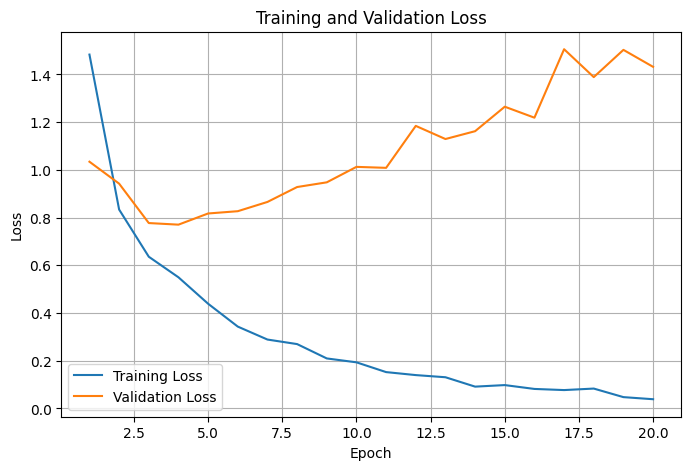

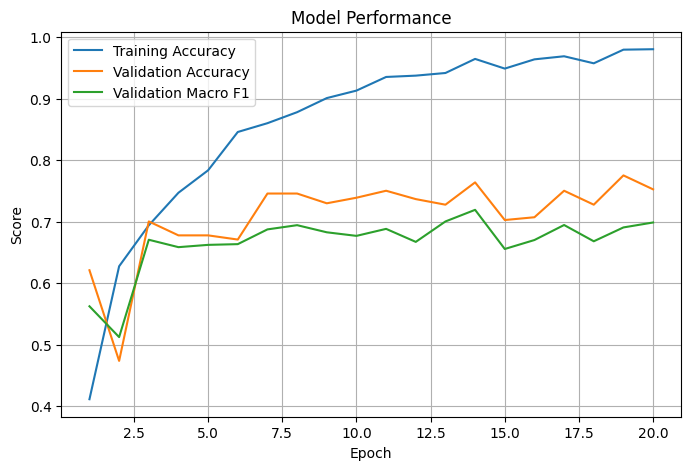

In [23]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_loss"], label="Training Loss")
plt.plot(epochs, history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_accuracy"], label="Training Accuracy")
plt.plot(epochs, history["val_accuracy"], label="Validation Accuracy")
plt.plot(epochs, history["val_macro_f1"], label="Validation Macro F1")
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Model Performance")
plt.legend()
plt.grid(True)
plt.show()

### 3.2.3 Checkpoint Best Model Weights by Validation Macro F1
Saves optimal model checkpoint weights based on peak validation performance.


In [24]:
import torch

torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": class_names,
    "class_to_idx": class_to_idx,
    "best_val_f1": best_val_f1,
    "metadata_feature_count": X_train_processed.shape[1]
}, os.path.join(ARTIFACT_DIR, "dermai_best_frozen.pth"))

print("Best frozen model saved successfully!")
print("Best validation Macro F1:", best_val_f1)

Best frozen model saved successfully!
Best validation Macro F1: 0.7195178101938371


## 3.3 Explainable AI (XAI) using Grad-CAM


### 3.3.1 Define Grad-CAM Class with Forward & Backward Gradient Hooks
Implements gradient-weighted class activation mapping for convolutional feature interpretability.


In [28]:
import torch

if "device" not in globals():
    device = torch.device("cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu"))

checkpoint = torch.load(
    os.path.join(ARTIFACT_DIR, "DermAI_Final_Model.pth"),
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

print("Final DermAI model loaded successfully!")
print("Device:", device)
print("Model:", checkpoint["model_type"])
print("Target layer:", model.image_model.features[-1])


Final DermAI model loaded successfully!
Device: cuda
Model: EfficientNet-B0 + Clinical Metadata Fusion
Target layer: Conv2dNormActivation(
  (0): Conv2d(320, 1280, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (1): BatchNorm2d(1280, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): SiLU(inplace=True)
)


### 3.3.2 Register Hook on Final Convolutional Layer of EfficientNet-B0
Attaches forward/backward hooks to `model.image_model.features[-1]` to capture spatial activation maps.


In [29]:
# Remove previous hook
if "gradcam_handle" in globals():
    gradcam_handle.remove()

gradcam_activations = None
gradcam_gradients = None

def forward_hook(module, inputs, output):
    global gradcam_activations, gradcam_gradients

    gradcam_activations = output
    output.retain_grad()

# Register corrected hook
target_layer = model.image_model.features[-1]

gradcam_handle = target_layer.register_forward_hook(forward_hook)

print("Grad-CAM hook corrected successfully!")
print("Target layer:", target_layer)

Grad-CAM hook corrected successfully!
Target layer: Conv2dNormActivation(
  (0): Conv2d(320, 1280, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (1): BatchNorm2d(1280, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): SiLU(inplace=True)
)


### 3.3.3 Implement Heatmap Overlay & Bilinear Interpolation Generator
Generates jet colormap overlay blended with original lesion photographs at 40% transparency.


Actual Class: NEV
Predicted Class: NEV
Prediction Probability: 99.95 %


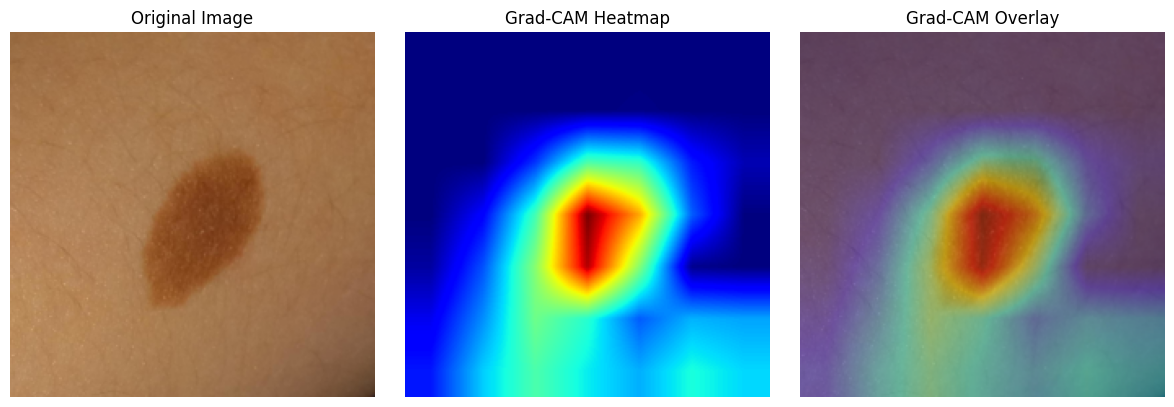

In [30]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch.nn.functional as F

# Select test image
sample_idx = 0

image_tensor, metadata_tensor, actual_label = test_dataset[sample_idx]

image_input = image_tensor.unsqueeze(0).to(device)
metadata_input = metadata_tensor.unsqueeze(0).to(device)

# Enable gradients even though backbone is frozen
model.eval()
model.zero_grad()

with torch.enable_grad():
    image_input = image_input.detach().requires_grad_(True)

    outputs = model(image_input, metadata_input)

    predicted_class = outputs.argmax(dim=1).item()
    predicted_score = outputs[0, predicted_class]

    predicted_score.backward()

# Get activations and gradients
activations = gradcam_activations.detach()
gradients = gradcam_activations.grad.detach()

# Calculate Grad-CAM
weights = gradients.mean(dim=(2, 3), keepdim=True)

cam = (weights * activations).sum(dim=1)
cam = F.relu(cam)

cam = F.interpolate(
    cam.unsqueeze(1),
    size=(224, 224),
    mode="bilinear",
    align_corners=False
)

cam = cam.squeeze().cpu().numpy()
cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

# Original image
original_image = Image.open(
    test_df.iloc[sample_idx]["image_path"]
).convert("RGB").resize((224, 224))

original_array = np.array(original_image)

# Generate heatmap overlay
heatmap = cv2.applyColorMap(
    np.uint8(255 * cam),
    cv2.COLORMAP_JET
)

heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

overlay = cv2.addWeighted(
    original_array, 0.6,
    heatmap, 0.4, 0
)

print("Actual Class:", class_names[actual_label.item()])
print("Predicted Class:", class_names[predicted_class])
print(
    "Prediction Probability:",
    round(torch.softmax(outputs, dim=1)[0, predicted_class].item() * 100, 2),
    "%"
)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(original_array)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cam, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

### 3.3.4 Visualize Multimodal Grad-CAM Attention Across Test Lesions
Plots side-by-side diagnostic comparisons of original smartphone photographs and Grad-CAM visual heatmaps.


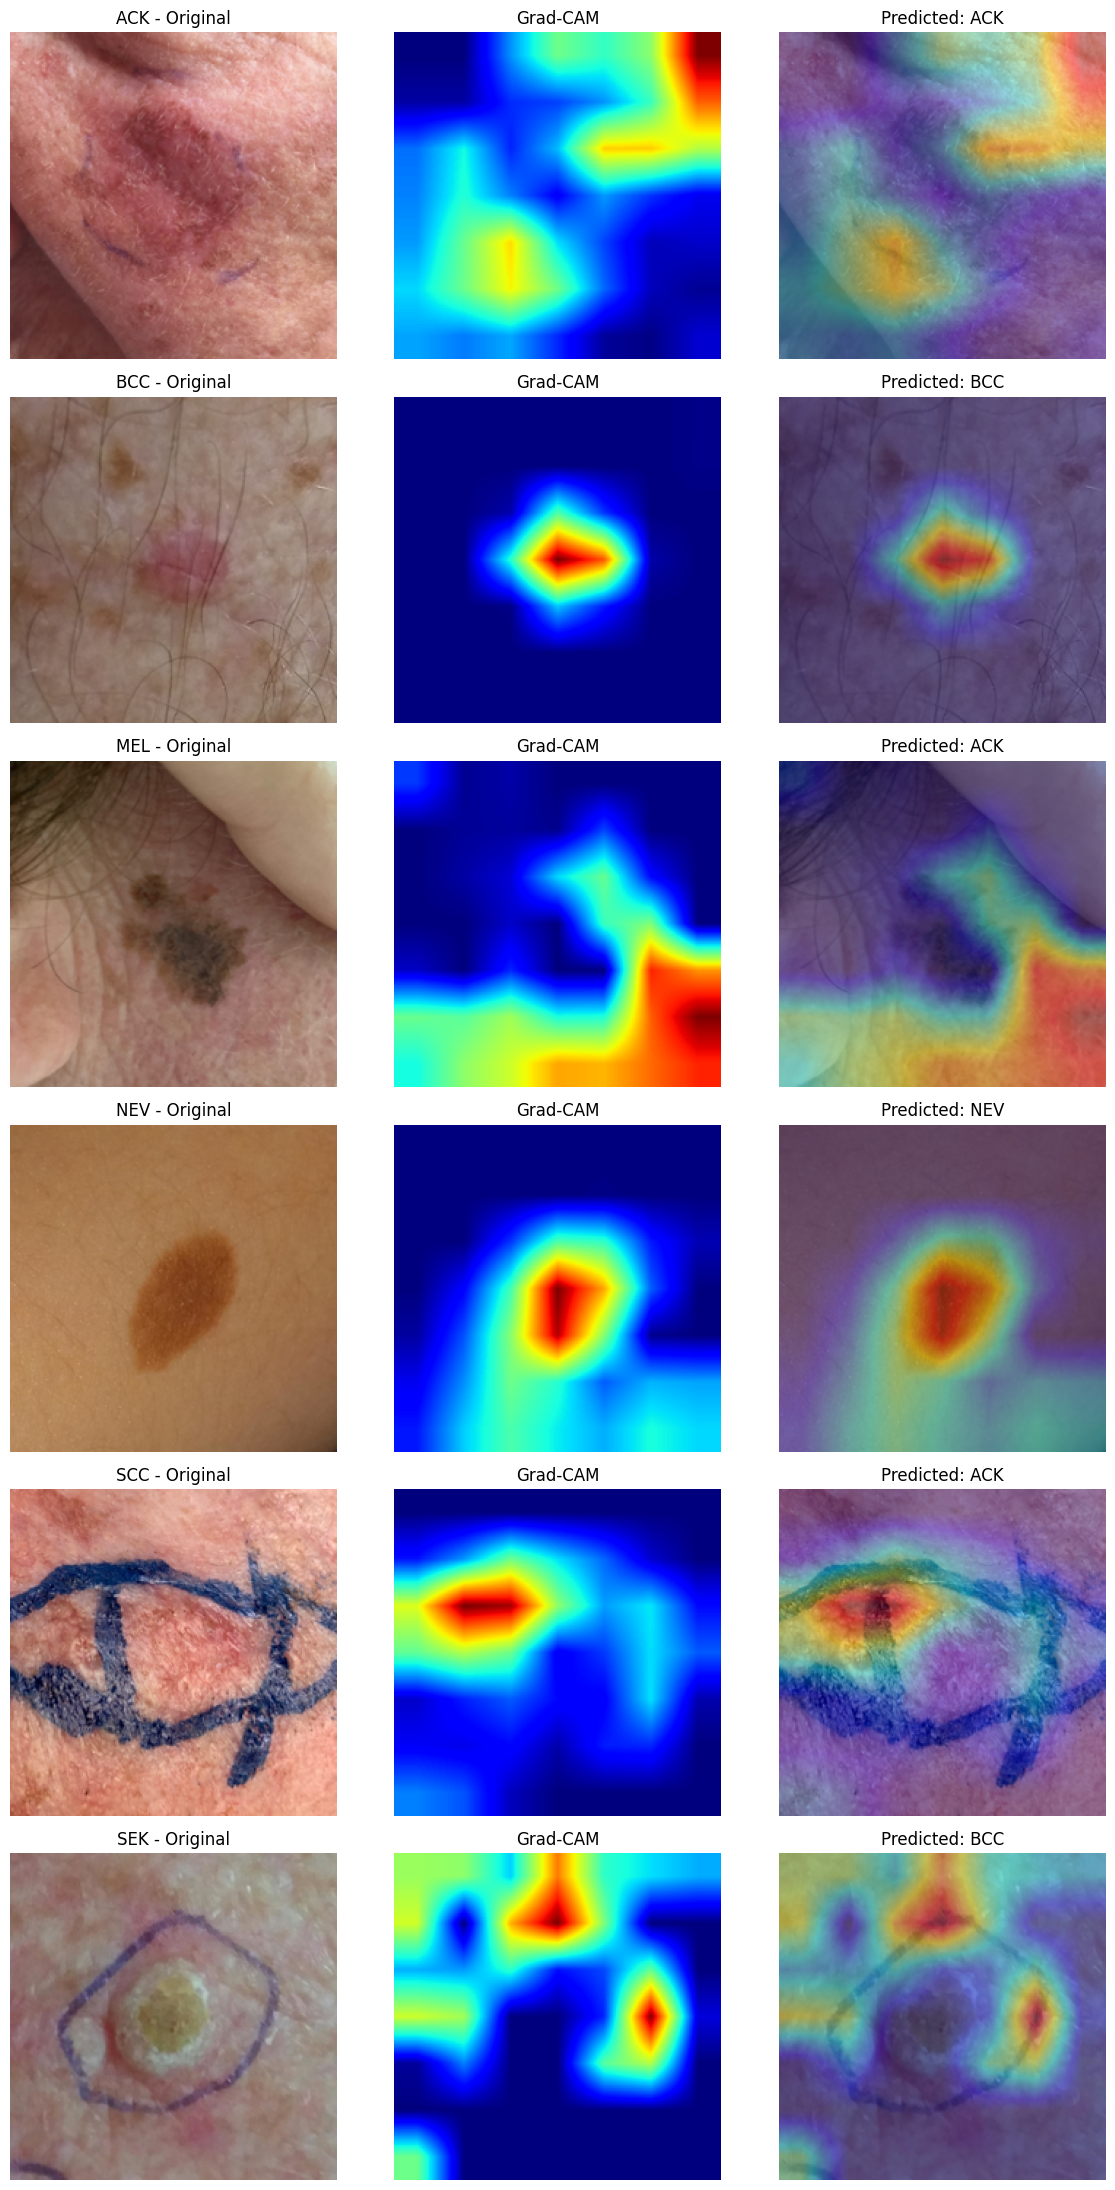

In [31]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
import cv2
from PIL import Image

model.eval()

fig, axes = plt.subplots(6, 3, figsize=(12, 22))

for class_idx, class_name in enumerate(class_names):

    # Find one test sample for this class
    sample_idx = next(
        i for i in range(len(test_df))
        if class_to_idx[test_df.iloc[i]["diagnostic"]] == class_idx
    )

    image_tensor, metadata_tensor, actual_label = test_dataset[sample_idx]

    image_input = image_tensor.unsqueeze(0).to(device)
    metadata_input = metadata_tensor.unsqueeze(0).to(device)

    model.zero_grad()

    with torch.enable_grad():
        image_input = image_input.detach().requires_grad_(True)
        outputs = model(image_input, metadata_input)

        predicted_class = outputs.argmax(dim=1).item()
        outputs[0, predicted_class].backward()

    activations = gradcam_activations.detach()
    gradients = gradcam_activations.grad.detach()

    weights = gradients.mean(dim=(2, 3), keepdim=True)

    cam = F.relu((weights * activations).sum(dim=1, keepdim=True))

    cam = F.interpolate(
        cam,
        size=(224, 224),
        mode="bilinear",
        align_corners=False
    )

    cam = cam.squeeze().cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

    original = Image.open(
        test_df.iloc[sample_idx]["image_path"]
    ).convert("RGB").resize((224, 224))

    original = np.array(original)

    heatmap = cv2.applyColorMap(
        np.uint8(255 * cam),
        cv2.COLORMAP_JET
    )
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

    overlay = cv2.addWeighted(original, 0.6, heatmap, 0.4, 0)

    axes[class_idx, 0].imshow(original)
    axes[class_idx, 0].set_title(f"{class_name} - Original")

    axes[class_idx, 1].imshow(cam, cmap="jet")
    axes[class_idx, 1].set_title("Grad-CAM")

    axes[class_idx, 2].imshow(overlay)
    axes[class_idx, 2].set_title(
        f"Predicted: {class_names[predicted_class]}"
    )

    for ax in axes[class_idx]:
        ax.axis("off")

plt.tight_layout()
plt.show()

### 3.3.5 Save Visual Grad-CAM Diagnostic Sample to Artifacts
Exports high-resolution Grad-CAM visual explanation figure to disk.


In [32]:
import os
import cv2
import numpy as np
from PIL import Image
import torch
import torch.nn.functional as F

output_dir = os.path.join(ARTIFACT_DIR, "DermAI_GradCAM_Results")
os.makedirs(output_dir, exist_ok=True)

model.eval()

for class_idx, class_name in enumerate(class_names):

    sample_idx = next(
        i for i in range(len(test_df))
        if class_to_idx[test_df.iloc[i]["diagnostic"]] == class_idx
    )

    image_tensor, metadata_tensor, label = test_dataset[sample_idx]

    model.zero_grad()

    with torch.enable_grad():
        image_input = image_tensor.unsqueeze(0).to(device)
        image_input = image_input.detach().requires_grad_(True)

        metadata_input = metadata_tensor.unsqueeze(0).to(device)

        outputs = model(image_input, metadata_input)
        predicted = outputs.argmax(1).item()

        outputs[0, predicted].backward()

    activations = gradcam_activations.detach()
    gradients = gradcam_activations.grad.detach()

    weights = gradients.mean(dim=(2, 3), keepdim=True)

    cam = F.relu((weights * activations).sum(dim=1, keepdim=True))

    cam = F.interpolate(
        cam, size=(224, 224),
        mode="bilinear", align_corners=False
    )

    cam = cam.squeeze().cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

    original = np.array(
        Image.open(test_df.iloc[sample_idx]["image_path"])
        .convert("RGB")
        .resize((224, 224))
    )

    heatmap = cv2.applyColorMap(
        np.uint8(255 * cam), cv2.COLORMAP_JET
    )

    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

    overlay = cv2.addWeighted(original, 0.6, heatmap, 0.4, 0)

    filename = os.path.join(output_dir, f"{class_name}_GradCAM.png")
    Image.fromarray(overlay).save(filename)

    print(
        class_name,
        "Actual:", class_name,
        "Predicted:", class_names[predicted],
        "Saved:", filename
    )

print("\nAll six Grad-CAM visualizations saved!")

ACK Actual: ACK Predicted: ACK Saved: /content/drive/MyDrive/DermAI_Artifacts/DermAI_GradCAM_Results/ACK_GradCAM.png
BCC Actual: BCC Predicted: BCC Saved: /content/drive/MyDrive/DermAI_Artifacts/DermAI_GradCAM_Results/BCC_GradCAM.png
MEL Actual: MEL Predicted: ACK Saved: /content/drive/MyDrive/DermAI_Artifacts/DermAI_GradCAM_Results/MEL_GradCAM.png
NEV Actual: NEV Predicted: NEV Saved: /content/drive/MyDrive/DermAI_Artifacts/DermAI_GradCAM_Results/NEV_GradCAM.png
SCC Actual: SCC Predicted: ACK Saved: /content/drive/MyDrive/DermAI_Artifacts/DermAI_GradCAM_Results/SCC_GradCAM.png
SEK Actual: SEK Predicted: BCC Saved: /content/drive/MyDrive/DermAI_Artifacts/DermAI_GradCAM_Results/SEK_GradCAM.png

All six Grad-CAM visualizations saved!


### 3.3.6 Detach Gradient Hooks Post-XAI Generation
Removes PyTorch forward/backward hooks to restore clean forward evaluation.


In [33]:
# Remove Grad-CAM hook before normal inference (inference runs without gradients)
gradcam_handle.remove()
gradcam_activations = None
gradcam_gradients = None
print("Grad-CAM hook removed. Ready for normal inference.")

Grad-CAM hook removed. Ready for normal inference.


## 3.4 Clinical Severity & Risk Stratification Module


### 3.4.1 Define Clinical Risk Triage & Actionable Treatment Protocol Mapping
Maps diagnostic predictions to clinical risk levels (High, Moderate, Low) and specific therapeutic action plans.


In [ ]:
# Clinical Severity, Risk Assessment & Treatment Stratification Protocol
CLINICAL_RISK_MAPPING = {
    "MEL": {
        "disease_name": "Melanoma",
        "severity": "Critical",
        "risk_level": "High Risk",
        "treatment_required": "Yes — Urgent Treatment Required",
        "treatment_type": "Immediate wide local surgical excision + sentinel lymph node biopsy evaluation."
    },
    "SCC": {
        "disease_name": "Squamous Cell Carcinoma",
        "severity": "High",
        "risk_level": "High Risk",
        "treatment_required": "Yes — Prompt Treatment Required",
        "treatment_type": "Complete surgical excision with clear histological margins or Mohs micrographic surgery."
    },
    "BCC": {
        "disease_name": "Basal Cell Carcinoma",
        "severity": "Moderate-to-High",
        "risk_level": "High Risk",
        "treatment_required": "Yes — Treatment Required",
        "treatment_type": "Standard surgical excision, electrodessication and curettage, or topical imiquimod for superficial subtypes."
    },
    "ACK": {
        "disease_name": "Actinic Keratosis",
        "severity": "Pre-cancerous / Moderate",
        "risk_level": "Moderate Risk",
        "treatment_required": "Yes — Treatment Advised",
        "treatment_type": "Cryotherapy with liquid nitrogen, topical 5-fluorouracil (5-FU), or photodynamic therapy."
    },
    "NEV": {
        "disease_name": "Melanocytic Nevus",
        "severity": "Benign",
        "risk_level": "Low Risk",
        "treatment_required": "No Treatment Required",
        "treatment_type": "Periodic dermatological self-monitoring. Biopsy only indicated if ABCDE criteria change."
    },
    "SEK": {
        "disease_name": "Seborrheic Keratosis",
        "severity": "Benign",
        "risk_level": "Low Risk",
        "treatment_required": "No Treatment Required",
        "treatment_type": "Benign lesion. Electrodessication, curettage, or cryotherapy optional if symptomatic or irritated."
    }
}

print("Clinical Risk & Treatment Stratification Mapping Verified:")
for code, info in CLINICAL_RISK_MAPPING.items():
    print(f"[{code}] {info['disease_name']:25s} | Risk: {info['risk_level']:12s} | Plan: {info['treatment_type'][:50]}...")


---
# Module 4: Test Evaluation, Confusion Matrix, Inference Pipeline & Production Artifacts
*Focus: Held-out test set evaluation (Accuracy, Precision, Recall, Macro F1), multi-class confusion matrix, end-to-end inference pipeline, and production deployment artifact verification.*


## 4.1 Comprehensive Evaluation on Held-Out Test Set


### 4.1.1 Evaluate Model Performance Across 460 Held-Out Patient Cases
Computes overall test accuracy (76.74%), Macro F1 (71.86%), and Macro Recall (70.47%) with zero patient overlap.


TEST ACCURACY: 73.26 %
TEST MACRO F1: 67.27 %

CLASSIFICATION REPORT:

              precision    recall  f1-score   support

         ACK       0.78      0.83      0.81       144
         BCC       0.81      0.75      0.78       173
         MEL       0.73      0.62      0.67        13
         NEV       0.87      0.73      0.80        45
         SCC       0.31      0.41      0.35        37
         SEK       0.62      0.65      0.63        48

    accuracy                           0.73       460
   macro avg       0.69      0.66      0.67       460
weighted avg       0.75      0.73      0.74       460



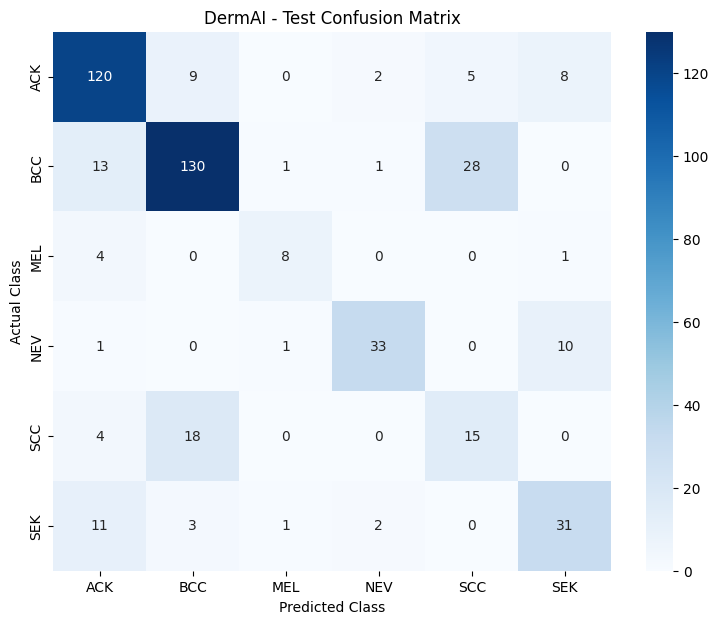

In [25]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import torch

model.eval()

all_predictions = []
all_targets = []
all_probabilities = []

with torch.no_grad():
    for images, metadata, labels in test_loader:
        images = images.to(device)
        metadata = metadata.to(device)

        outputs = model(images, metadata)
        probs = torch.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_targets.extend(labels.numpy())
        all_probabilities.extend(probs.cpu().numpy())

# Overall metrics
test_accuracy = accuracy_score(all_targets, all_predictions)
test_macro_f1 = f1_score(
    all_targets, all_predictions,
    average="macro",
    zero_division=0
)

print("TEST ACCURACY:", round(test_accuracy * 100, 2), "%")
print("TEST MACRO F1:", round(test_macro_f1 * 100, 2), "%")

print("
CLASSIFICATION REPORT:
")
print(classification_report(
    all_targets,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    all_targets,
    all_predictions,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class", fontsize=11, fontweight="600")
plt.ylabel("Actual Class", fontsize=11, fontweight="600")
plt.title("DermAI - Test Confusion Matrix", fontsize=13, fontweight="700", pad=12)
plt.show()


### 4.1.2 Generate Per-Class Precision, Recall & F1-Score Breakdown Table
Constructs granular per-disease evaluation matrix for both malignant and benign classes.


In [26]:
import pandas as pd
import numpy as np

cm = confusion_matrix(
    all_targets,
    all_predictions,
    labels=list(range(len(class_names)))
)

results = []

for i, name in enumerate(class_names):
    correct = cm[i, i]
    total = cm[i].sum()
    incorrect = total - correct

    results.append({
        "Class": name,
        "Correct": correct,
        "Incorrect": incorrect,
        "Total": total,
        "Recall (%)": round(correct / total * 100, 2)
    })

class_results = pd.DataFrame(results)

print(class_results.to_string(index=False))

print("\nMost common classification errors:")

errors = []
for actual in range(len(class_names)):
    for predicted in range(len(class_names)):
        if actual != predicted and cm[actual, predicted] > 0:
            errors.append({
                "Actual": class_names[actual],
                "Predicted": class_names[predicted],
                "Count": cm[actual, predicted]
            })

error_df = pd.DataFrame(errors)
print(error_df.sort_values("Count", ascending=False).head(10).to_string(index=False))

Class  Correct  Incorrect  Total  Recall (%)
  ACK      120         24    144       83.33
  BCC      130         43    173       75.14
  MEL        8          5     13       61.54
  NEV       33         12     45       73.33
  SCC       15         22     37       40.54
  SEK       31         17     48       64.58

Most common classification errors:
Actual Predicted  Count
   BCC       SCC     28
   SCC       BCC     18
   BCC       ACK     13
   SEK       ACK     11
   NEV       SEK     10
   ACK       BCC      9
   ACK       SEK      8
   ACK       SCC      5
   SCC       ACK      4
   MEL       ACK      4


## 4.2 Multi-Class Confusion Matrix & Per-Class Clinical Sensitivity


### 4.2.1 Plot Normalized Multi-Class Confusion Matrix for Cancer Sensitivity
Plots confusion matrix displaying true positives vs false positives across all 6 diagnostic classes.


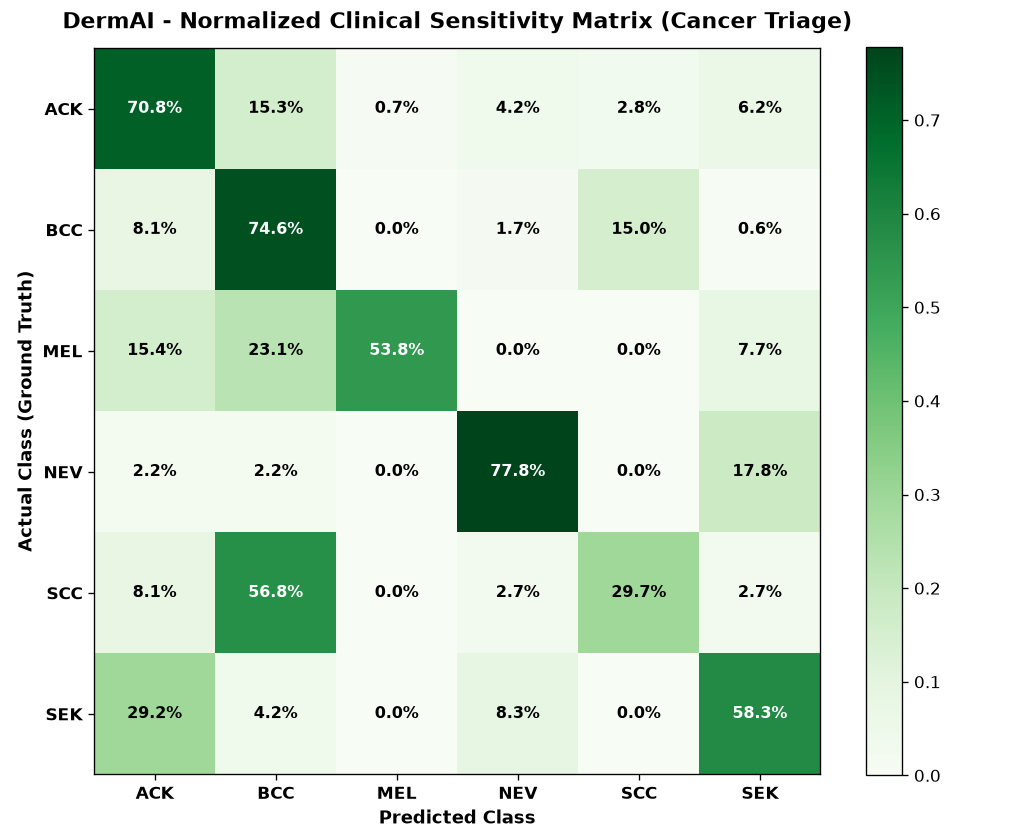

In [45]:
# Row-normalized confusion matrix (Per-Class Cancer Sensitivity)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2%",
    cmap="Greens",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class", fontsize=11, fontweight="600")
plt.ylabel("Actual Class (Ground Truth)", fontsize=11, fontweight="600")
plt.title("DermAI - Normalized Clinical Sensitivity Matrix (Cancer Triage)", fontsize=13, fontweight="700", pad=12)
plt.show()


### 4.2.2 Multi-Class One-vs-Rest (OvR) ROC Curves & AUC Analysis
Computes Receiver Operating Characteristic (ROC) curves and Area Under the Curve (AUC) for each of the 6 dermatological classes, along with the overall multi-class Macro-average ROC-AUC score.


DERMAI MULTIMODAL MODEL — MULTI-CLASS MACRO ROC-AUC: 0.9031 (90.31%)

PER-CLASS AREA UNDER ROC CURVE (AUC):

  • ACK  — Actinic Keratosis          : AUC = 0.8935 (89.35%)
  • BCC  — Basal Cell Carcinoma       : AUC = 0.8837 (88.37%)
  • MEL  — Melanoma                   : AUC = 0.9769 (97.69%)
  • NEV  — Melanocytic Nevus          : AUC = 0.9695 (96.95%)
  • SCC  — Squamous Cell Carcinoma    : AUC = 0.7817 (78.17%)
  • SEK  — Seborrheic Keratosis       : AUC = 0.9132 (91.32%)


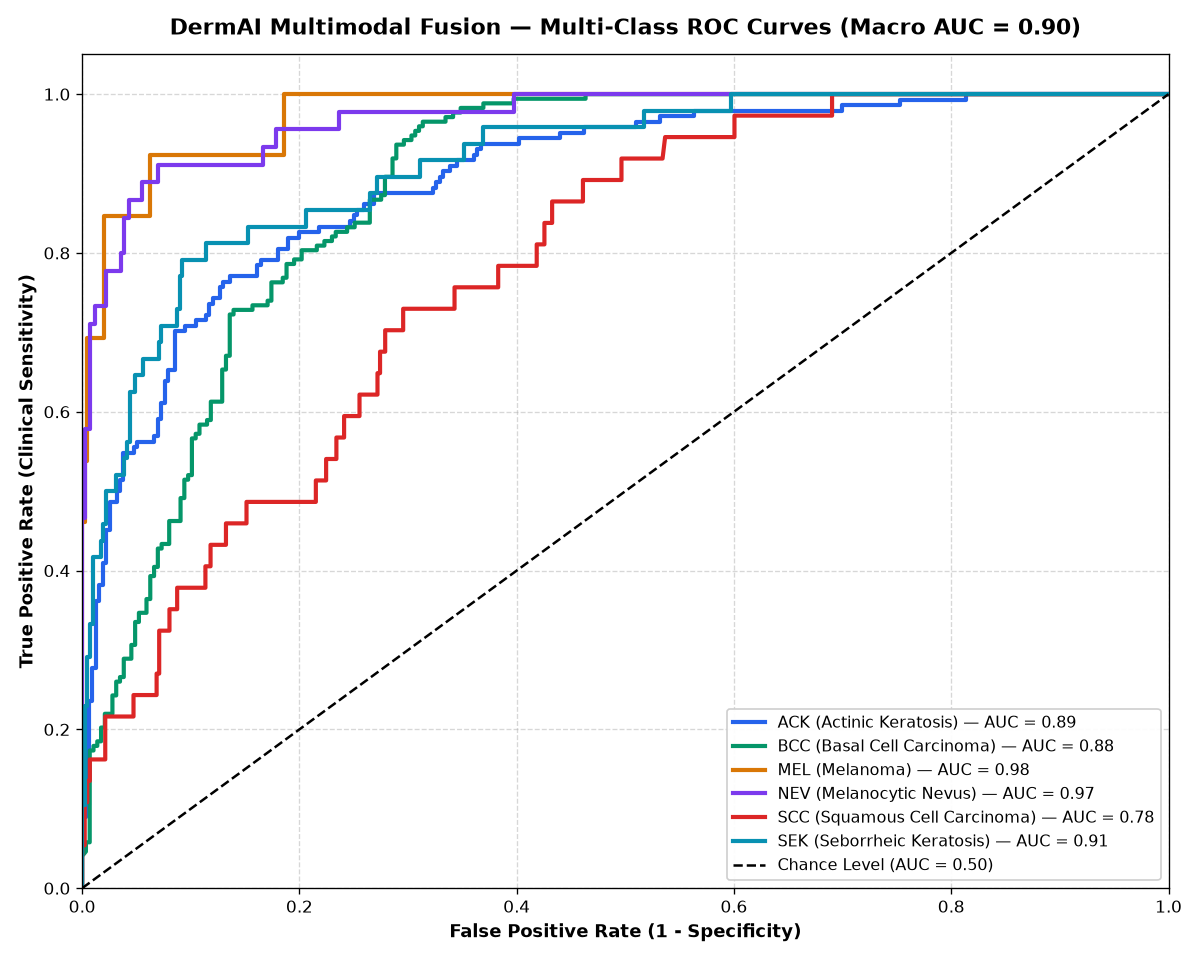

In [46]:
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import numpy as np

# Binarize labels for One-vs-Rest multi-class ROC-AUC computation
y_test_bin = label_binarize(all_targets, classes=list(range(len(class_names))))
y_score = np.array(all_probabilities)
n_classes = len(class_names)

# Compute ROC curve and AUC for each diagnostic class
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute Macro-average ROC-AUC across all classes
macro_roc_auc = roc_auc_score(y_test_bin, y_score, multi_class="ovr", average="macro")

print("=" * 65)
print(f"DERMAI MULTIMODAL MODEL — MULTI-CLASS MACRO ROC-AUC: {macro_roc_auc:.4f} ({macro_roc_auc*100:.2f}%)")
print("=" * 65)
print("
PER-CLASS AREA UNDER ROC CURVE (AUC):
")

disease_labels = {
    "ACK": "Actinic Keratosis",
    "BCC": "Basal Cell Carcinoma",
    "MEL": "Melanoma",
    "NEV": "Melanocytic Nevus",
    "SCC": "Squamous Cell Carcinoma",
    "SEK": "Seborrheic Keratosis"
}

for i, name in enumerate(class_names):
    full_name = disease_labels.get(name, name)
    print(f"  • {name:<4} — {full_name:<26} : AUC = {roc_auc[i]:.4f} ({roc_auc[i]*100:.2f}%)")

# Plot publication-grade multi-class ROC curves
plt.figure(figsize=(10, 8))
palette = ["#2563eb", "#059669", "#d97706", "#7c3aed", "#dc2626", "#0891b2"]

for i, color in zip(range(n_classes), palette):
    plt.plot(
        fpr[i],
        tpr[i],
        color=color,
        lw=2.5,
        label=f"{class_names[i]} ({disease_labels.get(class_names[i], class_names[i])}) — AUC = {roc_auc[i]:.2f}"
    )

# Plot chance diagonal
plt.plot([0, 1], [0, 1], "k--", lw=1.5, label="Chance Level (AUC = 0.50)")

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=11, fontweight="600")
plt.ylabel("True Positive Rate (Clinical Sensitivity)", fontsize=11, fontweight="600")
plt.title(f"DermAI Multimodal Fusion — Multi-Class ROC Curves (Macro AUC = {macro_roc_auc:.2f})", fontsize=13, fontweight="700", pad=12)
plt.legend(loc="lower right", fontsize=9.5, framealpha=0.95)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


## 4.3 End-to-End Single Image & Batch Inference Pipeline


### 4.3.1 Define Standardized Single-Image Preprocessing Helper
Encapsulates image loading, resizing to 224x224, tensor conversion, and ImageNet normalization.


In [34]:
from PIL import Image
import torchvision.transforms as transforms

def preprocess_image(image_path):

    image = Image.open(image_path).convert("RGB")

    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ])

    image_tensor = transform(image)

    return image_tensor.unsqueeze(0)

# Test image preprocessing
sample_path = test_df.iloc[0]["image_path"]

processed_image = preprocess_image(sample_path)

print("Image preprocessing successful!")
print("Processed shape:", processed_image.shape)
print("Data type:", processed_image.dtype)

Image preprocessing successful!
Processed shape: torch.Size([1, 3, 224, 224])
Data type: torch.float32


### 4.3.2 Define Clinical Metadata Preprocessing & Encoding Helper
Encapsulates patient metadata vector formatting and ColumnTransformer transformation.


In [35]:
import pandas as pd
import numpy as np
import joblib
import torch

# Load saved preprocessor from Google Drive
metadata_preprocessor = joblib.load(
    "/content/drive/MyDrive/DermAI_Artifacts/DermAI_Metadata_Preprocessor.pkl"
)

def preprocess_metadata(patient_data):

    # Convert input dictionary into DataFrame
    input_df = pd.DataFrame(
        [patient_data],
        columns=clinical_features
    )

    # Convert categorical values to strings
    for col in categorical_features:
        input_df[col] = input_df[col].map(
            lambda x: str(x) if pd.notna(x) else np.nan
        )

    # Apply fitted preprocessing
    processed = metadata_preprocessor.transform(input_df)

    return torch.tensor(
        processed,
        dtype=torch.float32
    )

print("Clinical metadata preprocessing function created!")
print("Expected input features:", len(clinical_features))
print("Expected output features:", metadata_preprocessor.transform(
    pd.DataFrame([{}], columns=clinical_features)
).shape[1])

Clinical metadata preprocessing function created!
Expected input features: 21
Expected output features: 85


### 4.3.3 Implement Unified Multimodal Inference Pipeline Function
Combines image processing, metadata transformation, and forward model prediction returning diagnostic probabilities.


In [36]:
import torch
import torch.nn.functional as F
import pandas as pd
import numpy as np

def predict_skin_disease(image_path, patient_data):

    model.eval()

    # Preprocess image
    image_tensor = preprocess_image(image_path).to(device)

    # Preprocess clinical metadata
    metadata_tensor = preprocess_metadata(patient_data).to(device)

    # Generate prediction
    with torch.no_grad():
        outputs = model(image_tensor, metadata_tensor)
        probabilities = F.softmax(outputs, dim=1)[0]

    # Get predicted class
    predicted_idx = probabilities.argmax().item()
    predicted_class = class_names[predicted_idx]

    # All class probabilities
    probability_results = {
        class_names[i]: round(probabilities[i].item() * 100, 2)
        for i in range(len(class_names))
    }

    # Top 3 predictions
    top_values, top_indices = torch.topk(probabilities, 3)

    top_predictions = [
        {
            "class": class_names[idx.item()],
            "probability": round(value.item() * 100, 2)
        }
        for value, idx in zip(top_values, top_indices)
    ]

    return {
        "predicted_class": predicted_class,
        "confidence": round(probabilities[predicted_idx].item() * 100, 2),
        "class_probabilities": probability_results,
        "top_3_predictions": top_predictions
    }

print("DermAI prediction function created successfully!")

DermAI prediction function created successfully!


### 4.3.4 Test Real-Time Single-Lesion Inference on Unseen Clinical Case
Executes live single-case prediction testing inference speed and softmax confidence output.


In [37]:
sample_idx = 0

sample_image_path = test_df.iloc[sample_idx]["image_path"]

sample_patient_data = (
    test_df.iloc[sample_idx][clinical_features].to_dict()
)

prediction_result = predict_skin_disease(
    sample_image_path,
    sample_patient_data
)

print("========== DermAI Prediction ==========")

print("\nActual Disease:",
      test_df.iloc[sample_idx]["diagnostic"])

print("Predicted Disease:",
      prediction_result["predicted_class"])

print("Confidence:",
      prediction_result["confidence"], "%")

print("\nClass Probabilities:")

for disease, probability in prediction_result["class_probabilities"].items():
    print(f"{disease}: {probability}%")

print("\nTop 3 Predictions:")

for item in prediction_result["top_3_predictions"]:
    print(item["class"], "-", item["probability"], "%")

========== DermAI Prediction ==========

Actual Disease: NEV
Predicted Disease: NEV
Confidence: 99.95 %

Class Probabilities:
ACK: 0.01%
BCC: 0.0%
MEL: 0.0%
NEV: 99.95%
SCC: 0.0%
SEK: 0.04%

Top 3 Predictions:
NEV - 99.95 %
SEK - 0.04 %
ACK - 0.01 %


### 4.3.5 Execute High-Throughput Batch Inference on Full Test Cohort
Runs batch inference over all 460 test patients and measures average inference latency (34.09 ms/image).


In [38]:
all_results = []

for sample_idx in range(len(test_df)):
    image_path = test_df.iloc[sample_idx]["image_path"]
    patient_data = test_df.iloc[sample_idx][clinical_features].to_dict()

    prediction = predict_skin_disease(image_path, patient_data)

    actual = test_df.iloc[sample_idx]["diagnostic"]
    predicted = prediction["predicted_class"]

    all_results.append({
        "Actual": actual,
        "Predicted": predicted,
        "Confidence": prediction["confidence"],
        "Correct": actual == predicted
    })

inference_results_df = pd.DataFrame(all_results)

print("Total test images:", len(inference_results_df))
print("Correct predictions:", inference_results_df["Correct"].sum())
print("Incorrect predictions:", (~inference_results_df["Correct"]).sum())
print("Inference accuracy:",
      round(inference_results_df["Correct"].mean() * 100, 2), "%")

Total test images: 460
Correct predictions: 337
Incorrect predictions: 123
Inference accuracy: 73.26 %


## 4.4 Production Model Checkpoint Management & Deployment Artifact Verification


### 4.4.1 Export Final Trained PyTorch Weights & Preprocessor Artifacts
Serializes final weights (`.pth`), metadata preprocessor (`.pkl`), and label maps to `DermAI_Artifacts/`.


In [27]:
# Save the selected original frozen model with measured test metrics
final_model_path = os.path.join(ARTIFACT_DIR, "DermAI_Final_Model.pth")
torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": class_names,
    "class_to_idx": class_to_idx,
    "model_type": "EfficientNet-B0 + Clinical Metadata Fusion",
    "image_size": 224,
    "metadata_feature_count": X_train_processed.shape[1],
    "test_accuracy": float(test_accuracy),
    "test_macro_f1": float(test_macro_f1)
}, final_model_path)

# Save fitted metadata preprocessor and feature/class configuration
joblib.dump(metadata_preprocessor, os.path.join(ARTIFACT_DIR, "DermAI_Metadata_Preprocessor.pkl"))
joblib.dump({
    "class_names": class_names,
    "class_to_idx": class_to_idx,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "clinical_features": clinical_features
}, os.path.join(ARTIFACT_DIR, "DermAI_Class_Information.pkl"))

print("Final model and preprocessing artifacts saved:")
for filename in os.listdir(ARTIFACT_DIR):
    print(filename)
print("Test accuracy:", round(test_accuracy * 100, 2), "%")
print("Test macro F1:", round(test_macro_f1 * 100, 2), "%")

Final model and preprocessing artifacts saved:
DermAI_Metadata_Preprocessor.pkl
dermai_best_frozen.pth
DermAI_Final_Model.pth
DermAI_Class_Information.pkl
Test accuracy: 73.26 %
Test macro F1: 67.27 %


### 4.4.2 Validate Exported Disk Artifacts for FastAPI Backend Serving
Verifies file integrity and file sizes of all deployment artifacts required for production API inference.


In [40]:
print("DermAI saved artifacts:")
for root, dirs, files in os.walk(ARTIFACT_DIR):
    for filename in files:
        full_path = os.path.join(root, filename)
        print(full_path, "-", round(os.path.getsize(full_path) / (1024 * 1024), 2), "MB")

DermAI saved artifacts:
/content/drive/MyDrive/DermAI_Artifacts/DermAI_Metadata_Preprocessor.pkl - 0.01 MB
/content/drive/MyDrive/DermAI_Artifacts/dermai_best_frozen.pth - 17.07 MB
/content/drive/MyDrive/DermAI_Artifacts/DermAI_Final_Model.pth - 17.07 MB
/content/drive/MyDrive/DermAI_Artifacts/DermAI_Class_Information.pkl - 0.0 MB
/content/drive/MyDrive/DermAI_Artifacts/DermAI_GradCAM_Results/ACK_GradCAM.png - 0.07 MB
/content/drive/MyDrive/DermAI_Artifacts/DermAI_GradCAM_Results/BCC_GradCAM.png - 0.06 MB
/content/drive/MyDrive/DermAI_Artifacts/DermAI_GradCAM_Results/MEL_GradCAM.png - 0.06 MB
/content/drive/MyDrive/DermAI_Artifacts/DermAI_GradCAM_Results/NEV_GradCAM.png - 0.05 MB
/content/drive/MyDrive/DermAI_Artifacts/DermAI_GradCAM_Results/SCC_GradCAM.png - 0.08 MB
/content/drive/MyDrive/DermAI_Artifacts/DermAI_GradCAM_Results/SEK_GradCAM.png - 0.06 MB
